# CS-781 Phase 1 — Architecture 4: RetNet from scratch

In this notebook I implement and train a RetNet (retentive network) language model from scratch, using **my own BPE tokenizer** and only the official Phase-1 corpus (streamed from Hugging Face `Exploration-Lab/CS-781-Capstone`). No pretrained weights are used.

**Model.** 12 layers, d_model 768, 6 heads (key dimension 128, value dimension 256), multi-scale retention with per-head decay γ_h = 1 − 2^(−5−h), swish gate and per-head GroupNorm, SwiGLU-style FFN (2048), tied embeddings, 137.9M parameters. The parallel, chunkwise and recurrent forms of retention are checked to give the same output.

**Training.** Multi-GPU DDP with mixed precision; the training time is computed from the session budget and the cosine learning-rate schedule ends exactly at that time. Checkpoints allow training to continue across sessions.

**Generation.** The prompt is read chunkwise and the continuation is decoded recurrently, trimmed to exactly 128 words, with the decoding setting chosen on held-out prompts.


## CELL 1 — Imports, switches and configuration

In [1]:
# CELL 1 — Imports, switches and configuration  (edit only this cell to change the experiment)
import os, sys, json, math, time, random, glob, shutil, subprocess, zipfile, re, copy, gc
import numpy as np
import torch

T0 = time.time()                       # start of this notebook session (used to fit training into Kaggle's 12 h limit)
DEBUG_TINY = False   # True = tiny model + tiny data: runs the WHOLE pipeline in minutes (run once to verify, then set False)
SESSION_LIMIT_H = 12.0                 # Kaggle session limit
RESERVE_H = 1.5                        # time kept free AFTER training for evaluation + test inference + zip + safety margin
INPUT_ROOT = os.environ.get("TXL_INPUT_ROOT", "/kaggle/input")
WORK       = os.environ.get("TXL_WORK", "/kaggle/working/retnet")
SUBMIT_DIR = os.environ.get("TXL_SUBMIT", "/kaggle/working")
os.makedirs(WORK, exist_ok=True); os.chdir(WORK); sys.path.insert(0, WORK)

CFG = dict(
    data=dict(seed=1234, sources=["acts", "high_courts", "supreme_court", "tribunals"],
              tokens_per_source=60_000_000,     # BPE tokens kept per source for TRAINING (4 x 60M = 240M tokens)
              val_frac=0.01,                    # fraction of DOCUMENTS (hash based) that go to validation
              chars_per_token=4.2, min_doc_tokens=32, max_doc_chars=400_000, max_scan_docs=None,
              chunk_chars=1_000_000,            # ~1 MB of text per processing chunk (stream -> chunk -> tokenise -> save -> clear)
              n_segments=128, commit_every=25), # hffs backend: windows spread over the file | progress commit every 25 chunks
    model=dict(d_model=768, n_layer=12, n_head=6, d_ff=2048, v_mult=2, dropout=0.1,
               seg_len=1024,                    # training segment (state is carried BETWEEN segments, detached)
               chunk=256,                       # chunk size of the chunkwise retention inside a segment
               tie_weights=True),
    train=dict(lanes_per_gpu=4, accum=2, peak_lr=4e-4, min_lr=4e-5, warmup_updates=300, weight_decay=0.1,
               betas=[0.9, 0.95], clip=1.0,
               target_tokens=1_500_000_000,     # upper bound; normally the TIME budget ends training first
               time_budget_hours=None,          # filled in CELL 14 from the session limit (LR cosine ends exactly at this time)
               session_hours=None,              # graceful stop inside this session
               eval_every=500, eval_lanes_per_gpu=4, eval_max_steps=60, save_every=400, log_every=25,
               stop_after_updates=0, amp=True, seed=1234),
)
if DEBUG_TINY:
    CFG["data"].update(tokens_per_source=150_000, val_frac=0.05, max_scan_docs=1500)
    CFG["model"].update(d_model=128, n_layer=2, n_head=2, d_ff=256, seg_len=64, chunk=16)
    CFG["train"].update(lanes_per_gpu=2, accum=2, warmup_updates=5, target_tokens=40_000, eval_every=10,
                        eval_lanes_per_gpu=2, eval_max_steps=6, save_every=5, log_every=2)

# Hugging Face source (streamed; NOTHING is downloaded to disk).  Token = Kaggle Secret named "HF" (Add-ons -> Secrets -> attach to notebook)
HF = dict(repo_id="Exploration-Lab/CS-781-Capstone", secret_name="HF",
          backend="auto",       # "auto": try datasets streaming=True in a memory-capped probe, fall back to HfFileSystem range streaming
                                # "datasets" / "hffs": force one
          files={"acts": "Phase_1_Pretraining/Train/train_acts.json",
                 "high_courts": "Phase_1_Pretraining/Train/train_high_courts.json",
                 "supreme_court": "Phase_1_Pretraining/Train/train_supreme_court.json",
                 "tribunals": "Phase_1_Pretraining/Train/train_tribunals.json"})

# decoding settings (validation checks + official inference) — edit freely to optimise the metric
GEN = dict(n_words=128, do_sample=False, temperature=0.8, top_k=50, top_p=0.92,
           rep_penalty=1.10, rep_window=128, no_repeat_ngram=4, max_new_tokens=450)

N_GPU = torch.cuda.device_count()
print("torch", torch.__version__, "| GPUs:", N_GPU, [torch.cuda.get_device_name(i) for i in range(N_GPU)])
print("DEBUG_TINY =", DEBUG_TINY, "| WORK =", WORK)


torch 2.11.0+cu128 | GPUs: 2 ['Tesla T4', 'Tesla T4']
DEBUG_TINY = False | WORK = /kaggle/working/retnet


## CELL 2 — Hugging Face token (Kaggle Secret HF), tokenizer, test file, old shards/checkpoints

In [2]:
# CELL 2 — Hugging Face access (token from Kaggle Secrets), tokenizer, test file, old shards/checkpoints.  The training corpus is NOT copied here.
try:
    import datasets, huggingface_hub
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "datasets", "huggingface_hub", "psutil"], check=True)
    import datasets, huggingface_hub
print("datasets", datasets.__version__, "| huggingface_hub", huggingface_hub.__version__)

def _find(pred, roots):
    hits = []
    for r in roots:
        if not os.path.isdir(r): continue
        for d, _, fs in os.walk(r):
            for f in fs:
                if pred(f, d): hits.append(os.path.join(d, f))
    return sorted(set(hits))
def _newest(paths): return max(paths, key=os.path.getmtime) if paths else None

# ---- token: Kaggle Secret "HF" (never printed)
HF_TOKEN = None
try:
    from kaggle_secrets import UserSecretsClient
    HF_TOKEN = UserSecretsClient().get_secret(HF["secret_name"])
except Exception as e:
    HF_TOKEN = os.environ.get("HF_TOKEN")
assert HF_TOKEN, ("No Hugging Face token found. Kaggle notebook: Add-ons -> Secrets -> add a secret named HF with your token "
                  "and tick 'Attached' for this notebook. Also switch Internet ON in the notebook settings.")
print(f"HF token found (length {len(HF_TOKEN)})")

# ---- check the 4 files exist in the repo (metadata only, no download)
HF_PATHS = {s: HF["files"][s] for s in CFG["data"]["sources"]}
try:
    infos = huggingface_hub.HfApi(token=HF_TOKEN).get_paths_info(HF["repo_id"], list(HF_PATHS.values()), repo_type="dataset")
    HF_SIZES = {i.path: i.size for i in infos}
except Exception as e:
    raise RuntimeError(f"Cannot reach {HF['repo_id']} on Hugging Face ({type(e).__name__}). Check: Internet ON, secret HF correct, repo/file names in CELL 1.") from e
for s, p in HF_PATHS.items():
    print(f"{s:14s} {HF_SIZES.get(p, 0)/2**30:6.2f} GB (stays on Hugging Face)  {p}")
    assert p in HF_SIZES, f"{p} not found in the repo"

# ---- test prompts, tokenizer (these two come from my Kaggle input datasets)
TEST_JSON = None   # <- set manually if auto-detection picks the wrong file
if TEST_JSON is None:
    hits = _find(lambda f, d: f.endswith(".json") and "test" in f.lower() and not f.startswith("train_"), [INPUT_ROOT])
    TEST_JSON = hits[0] if hits else None
tok_hits = _find(lambda f, d: f == "bpe_tokenizer.json", [INPUT_ROOT, WORK, "/kaggle/working"])
py_hits  = _find(lambda f, d: f == "a1_tokenizer.py", [INPUT_ROOT, WORK, "/kaggle/working"])
if not tok_hits or not py_hits:
    raise FileNotFoundError("Add bpe_tokenizer.json and a1_tokenizer.py to the notebook (as a Kaggle dataset).")
TOK_JSON = tok_hits[0]
if os.path.abspath(py_hits[0]) != os.path.join(WORK, "a1_tokenizer.py"):
    shutil.copy(py_hits[0], os.path.join(WORK, "a1_tokenizer.py"))

# ---- processed shards from an earlier session (reuse instead of re-streaming)
DATA_DIR = os.path.join(WORK, "data")
for m in _find(lambda f, d: f == "meta.json" and os.path.basename(d) == "data", [WORK, INPUT_ROOT]):
    try:
        if "dtype" in json.load(open(m)): DATA_DIR = os.path.dirname(m); break
    except Exception: pass

CKPT_DIR = os.path.join(WORK, "ckpt"); os.makedirs(CKPT_DIR, exist_ok=True)
RESUME_CKPT = _newest(_find(lambda f, d: f == "last.pt", [WORK, INPUT_ROOT]))
CFG["paths"] = dict(data_dir=DATA_DIR, ckpt_dir=CKPT_DIR, work=WORK, tok_json=TOK_JSON)
P = CFG["paths"]
CFG_PATH = os.path.join(WORK, "config.json")
json.dump(CFG, open(CFG_PATH, "w"), indent=1)       # (the token is NOT part of CFG)
print("test file     :", TEST_JSON)
print("tokenizer     :", TOK_JSON)
print("data dir      :", DATA_DIR, "(existing shards -> no streaming needed)" if os.path.exists(os.path.join(DATA_DIR, "meta.json")) else "(will be created by streaming)")
print("resume ckpt   :", RESUME_CKPT)


datasets 4.8.5 | huggingface_hub 1.29.0
HF token found (length 37)
acts             0.68 GB (stays on Hugging Face)  Phase_1_Pretraining/Train/train_acts.json
high_courts      9.94 GB (stays on Hugging Face)  Phase_1_Pretraining/Train/train_high_courts.json
supreme_court    1.23 GB (stays on Hugging Face)  Phase_1_Pretraining/Train/train_supreme_court.json
tribunals        6.04 GB (stays on Hugging Face)  Phase_1_Pretraining/Train/train_tribunals.json
test file     : /kaggle/input/datasets/alex595786/phase1-test/test.json
tokenizer     : /kaggle/input/datasets/alex595786/bpe-tokenizer/bpe_tokenizer.json
data dir      : /kaggle/working/retnet/data (will be created by streaming)
resume ckpt   : None


## CELL 3 — Write `ret_model.py` (RetNet from scratch: retention, 3 forms, document-aware state)

In [3]:
%%writefile ret_model.py
"""RetNet (Sun et al., 2023, "Retentive Network: A Successor to Transformer for LLMs") from scratch in PyTorch.

Retention (per head, decay gamma):      o_n = sum_{m<=n} gamma^(n-m) (Q_n e^{i n theta}) (K_m e^{i m theta})^H v_m
  parallel form   : (Q K^T  .*  D) V                      D_nm = gamma^(n-m) for n>=m
  recurrent form  : S_n = gamma S_{n-1} + K_n^T v_n ;  o_n = Q_n S_n
  chunkwise form  : parallel inside a chunk + recurrent state between chunks     (used for training / prompt reading)
ONE function (`retention_chunk`) implements the chunkwise form; chunk = whole sequence gives the parallel form and
chunk = 1 gives the recurrent form, so the three forms are numerically identical (checked in the notebook).

Document-aware: tokens carry a document id; inner-chunk scores are masked to the same document, and the carried state is
only readable by tokens of the document that produced it (state reset at document boundaries, even mid-chunk).
"""
import math
import torch
import torch.nn as nn
import torch.nn.functional as F

PAD_ID, UNK_ID, BOS_ID, EOS_ID = 0, 1, 2, 3
IGNORE, DOC_EMPTY, DOC_PAD = -100, -2, -1


def rotate(x, cos, sin):
    """Rotary / xPos-style rotation e^{i n theta} of query/key vectors.  x [B,L,H,dk]; cos,sin [B,L,1,dk/2]."""
    x1, x2 = x.chunk(2, dim=-1)
    return torch.cat([x1 * cos - x2 * sin, x2 * cos + x1 * sin], dim=-1)


def retention_chunk(q, k, v, doc, S, prev_doc, log_gamma):
    """q,k [B,H,C,dk] (q already scaled)  v [B,H,C,dv]  doc [B,C]  S [B,H,dk,dv]  prev_doc [B]  log_gamma [H]   (all float32)
    returns out [B,H,C,dv], new state S [B,H,dk,dv], doc id of the last token (-> next prev_doc)."""
    B, H, C, _ = q.shape
    dev = q.device
    i = torch.arange(C, device=dev, dtype=torch.float32)
    lg = log_gamma.view(H, 1, 1)
    diff = i.view(C, 1) - i.view(1, C)
    D = torch.exp(lg * diff.clamp(min=0)) * (diff >= 0)                 # [H,C,C]  gamma^(n-m), causal
    same = (doc.unsqueeze(2) == doc.unsqueeze(1)).unsqueeze(1)          # [B,1,C,C] same-document mask
    scores = torch.matmul(q, k.transpose(-1, -2)) * D.unsqueeze(0) * same
    inner = torch.matmul(scores, v)                                      # (Q K^T .* D) V       (inside the chunk)
    lgv = log_gamma.view(1, H, 1, 1)
    xi = torch.exp(lgv * (i + 1).view(1, 1, C, 1))                       # gamma^(i+1): decay of the old state at position i
    cont = (doc == prev_doc.unsqueeze(1)).view(B, 1, C, 1).to(q.dtype)   # only tokens of the document that owns the state
    cross = torch.matmul(q, S) * xi * cont                               # Q S_prev            (before the chunk)
    last = doc[:, -1]
    zeta = torch.exp(lgv * (C - 1 - i).view(1, 1, C, 1))                 # gamma^(C-1-j): decay of chunk tokens at chunk end
    w = (doc == last.unsqueeze(1)).view(B, 1, C, 1).to(q.dtype)          # only tokens of the LAST document enter the new state
    kv = torch.matmul((k * zeta * w).transpose(-1, -2), v)               # sum_j gamma^(C-1-j) K_j^T v_j
    keep = (last == prev_doc).view(B, 1, 1, 1).to(q.dtype)               # old state survives only if the chunk stays in its document
    S_new = keep * torch.exp(lgv * C) * S + kv
    return inner + cross, S_new, last


class MultiScaleRetention(nn.Module):
    def __init__(self, d_model, n_head, d_k, d_v):
        super().__init__()
        self.H, self.dk, self.dv = n_head, d_k, d_v
        self.wq = nn.Linear(d_model, n_head * d_k, bias=False)
        self.wk = nn.Linear(d_model, n_head * d_k, bias=False)
        self.wv = nn.Linear(d_model, n_head * d_v, bias=False)
        self.wg = nn.Linear(d_model, n_head * d_v, bias=False)          # swish gate
        self.wo = nn.Linear(n_head * d_v, d_model, bias=False)
        self.gn_w = nn.Parameter(torch.ones(n_head * d_v))               # GroupNorm (one group per head)
        self.gn_b = nn.Parameter(torch.zeros(n_head * d_v))
        gamma = 1.0 - 2.0 ** (-5.0 - torch.arange(n_head).float())       # paper: gamma = 1 - 2^(-5-h)
        self.register_buffer("log_gamma", gamma.log(), persistent=False)

    def forward(self, x, cos, sin, doc, S, prev_doc, chunk):
        B, L, _ = x.shape
        H, dk, dv = self.H, self.dk, self.dv
        q = self.wq(x).view(B, L, H, dk); k = self.wk(x).view(B, L, H, dk)
        v = self.wv(x).view(B, L, H, dv); g = self.wg(x)
        with torch.autocast(device_type=x.device.type, enabled=False):    # retention core in FP32 (decay products are delicate)
            q = (rotate(q.float(), cos, sin) * dk ** -0.5).transpose(1, 2).contiguous()
            k = rotate(k.float(), cos, sin).transpose(1, 2).contiguous()
            v = v.float().transpose(1, 2).contiguous()
            outs, prev = [], prev_doc
            for a in range(0, L, chunk):
                b = min(L, a + chunk)
                o, S, prev = retention_chunk(q[:, :, a:b], k[:, :, a:b], v[:, :, a:b], doc[:, a:b], S, prev, self.log_gamma)
                outs.append(o)
            o = torch.cat(outs, dim=2).transpose(1, 2).reshape(B * L, H * dv)
            o = F.group_norm(o, H, self.gn_w.float(), self.gn_b.float(), 1e-5)
        o = o.view(B, L, H * dv)
        return self.wo(F.silu(g) * o.to(g.dtype)), S


class RetBlock(nn.Module):
    def __init__(self, d_model, n_head, d_k, d_v, d_ff, dropout):
        super().__init__()
        self.ln1, self.ln2 = nn.LayerNorm(d_model), nn.LayerNorm(d_model)
        self.msr = MultiScaleRetention(d_model, n_head, d_k, d_v)
        self.gate, self.up = nn.Linear(d_model, d_ff, bias=False), nn.Linear(d_model, d_ff, bias=False)
        self.down = nn.Linear(d_ff, d_model, bias=False)
        self.drop = nn.Dropout(dropout)

    def forward(self, x, cos, sin, doc, S, prev_doc, chunk):
        a, S = self.msr(self.ln1(x), cos, sin, doc, S, prev_doc, chunk)
        x = x + self.drop(a)
        y = self.ln2(x)
        return x + self.drop(self.down(F.silu(self.gate(y)) * self.up(y))), S


class RetNet(nn.Module):
    def __init__(self, vocab_size, d_model=768, n_layer=12, n_head=6, d_ff=2048, v_mult=2, dropout=0.1,
                 seg_len=1024, chunk=256, tie_weights=True, **_):
        super().__init__()
        assert d_model % n_head == 0 and (d_model // n_head) % 2 == 0
        self.vocab_size, self.d_model, self.n_layer, self.H = vocab_size, d_model, n_layer, n_head
        self.dk, self.dv = d_model // n_head, v_mult * d_model // n_head
        self.seg_len, self.chunk = seg_len, chunk
        self.emb = nn.Embedding(vocab_size, d_model)
        self.drop = nn.Dropout(dropout)
        self.layers = nn.ModuleList([RetBlock(d_model, n_head, self.dk, self.dv, d_ff, dropout) for _ in range(n_layer)])
        self.final_ln = nn.LayerNorm(d_model)
        self.lm_head = nn.Linear(d_model, vocab_size, bias=False)
        self.register_buffer("inv_freq", 1.0 / (10000 ** (torch.arange(0, self.dk, 2).float() / self.dk)), persistent=False)
        for m in self.modules():
            if isinstance(m, (nn.Linear, nn.Embedding)):
                nn.init.normal_(m.weight, 0.0, 0.02)
        std = 0.02 / math.sqrt(2 * n_layer)
        for blk in self.layers:
            nn.init.normal_(blk.msr.wo.weight, 0.0, std); nn.init.normal_(blk.down.weight, 0.0, std)
        if tie_weights:
            self.lm_head.weight = self.emb.weight

    def init_state(self, B, device):
        S = [torch.zeros(B, self.H, self.dk, self.dv, device=device) for _ in range(self.n_layer)]
        return S, torch.full((B,), DOC_EMPTY, dtype=torch.long, device=device)

    def hidden(self, x, doc, pos, states, prev_doc, chunk=None):
        """x,doc,pos [B,L] long (pos = position INSIDE the document).  Returns h [B,L,d], new (detached) states, new prev_doc."""
        chunk = chunk or self.chunk
        h = self.drop(self.emb(x))
        ang = pos.float().unsqueeze(-1) * self.inv_freq
        cos, sin = ang.cos().unsqueeze(2), ang.sin().unsqueeze(2)
        new_states = []
        for blk, S in zip(self.layers, states):
            h, S2 = blk(h, cos, sin, doc, S, prev_doc, chunk)
            new_states.append(S2.detach())                                  # stop-gradient between segments
        return self.final_ln(h), new_states, doc[:, -1].detach()

    def forward(self, x, y, doc, pos, states, prev_doc):
        h, ns, npd = self.hidden(x, doc, pos, states, prev_doc)
        logits = self.lm_head(h)
        loss_sum = F.cross_entropy(logits.float().view(-1, self.vocab_size), y.reshape(-1), ignore_index=IGNORE, reduction="sum")
        return loss_sum, (y != IGNORE).sum(), ns, npd

    def logits(self, x, doc, pos, states, prev_doc, chunk=None):
        h, ns, npd = self.hidden(x, doc, pos, states, prev_doc, chunk)
        return self.lm_head(h), ns, npd


def count_params(model):
    return sum(p.numel() for p in model.parameters()), sum(p.numel() for p in model.parameters() if p.requires_grad)


Writing ret_model.py


## CELL 4 — Write `ret_data.py` (fast streaming, document-level split, BPE shards, document-aware lanes)

In [4]:
%%writefile ret_data.py
"""Streaming JSON reader, document-level split, parallel BPE tokenisation to on-disk shards,
and document-aware 'lane' batching for RetNet (recurrent state needs consecutive segments)."""
import os, sys, re, json, time, heapq, hashlib
import multiprocessing as mp
from collections import deque
import numpy as np

BOS_ID, EOS_ID, IGNORE = 2, 3, -100
TEXT_KEYS = ("text", "judgment", "judgement", "content", "body", "full_text")


# ----------------------------------------------------------------------------- reading
def stream_json_array(path, chunk_chars=1 << 24):
    """Yield the objects of a (huge) top-level JSON array one by one, never holding more than ~1 chunk.
    `path` may be a file path or an open BINARY file-like object (e.g. a remote Hugging Face file)."""
    import io
    dec = json.JSONDecoder()
    if isinstance(path, (str, os.PathLike)):
        f = open(path, "r", encoding="utf-8", errors="replace")
    else:
        f = io.TextIOWrapper(path, encoding="utf-8", errors="replace")
    st = {"buf": "", "pos": 0, "eof": False}

    def refill():
        chunk = f.read(chunk_chars)
        if not chunk:
            st["eof"] = True
            return False
        st["buf"] = st["buf"][st["pos"]:] + chunk
        st["pos"] = 0
        return True

    started = False
    try:
        while True:
            while True:                                   # skip whitespace / commas
                buf, pos = st["buf"], st["pos"]
                while pos < len(buf) and buf[pos] in " \t\r\n,":
                    pos += 1
                st["pos"] = pos
                if pos < len(buf):
                    break
                if not refill():
                    return
            c = st["buf"][st["pos"]]
            if c == "[" and not started:
                started = True; st["pos"] += 1; continue
            if c == "]":
                return
            while True:
                try:
                    obj, end = dec.raw_decode(st["buf"], st["pos"]); break
                except json.JSONDecodeError:
                    if not refill():
                        raise
            st["pos"] = end
            yield obj
    finally:
        f.close()


def get_text(rec):
    if isinstance(rec, str):
        return rec
    for k in TEXT_KEYS:
        v = rec.get(k)
        if isinstance(v, str) and v.strip():
            return v
    best = ""
    for v in rec.values():                                 # fallback: longest string field
        if isinstance(v, str) and len(v) > len(best):
            best = v
    return best


_NL3 = re.compile(r"\n{3,}")
def clean_text(t):
    """Same normalisation for training text and test prompts."""
    return _NL3.sub("\n\n", t.replace("\r", "")).strip()


def doc_hash(source, text):
    d = hashlib.md5((source + "\x00" + str(len(text)) + "\x00" + text[:400]).encode("utf-8", "ignore")).digest()
    h = int.from_bytes(d[:8], "big")
    return h, (h & 0xFFFFFFFF) / 2 ** 32, (h >> 32) / 2 ** 32      # key, keep-uniform, split-uniform



def iter_docs(path):
    """Yield (basis, payload) for every document.  FAST PATH: when the file has one JSON object per line (as the official files
    do) lines are read as raw bytes and are only JSON-parsed if the document is actually kept (skipping ~10 GB of parsing).
    FALLBACK: generic incremental parser.  `basis` identifies the document for hashing."""
    fast = False
    with open(path, "rb") as f:
        tested = 0
        for line in f:
            ls = line.strip()
            if ls in (b"[", b"]", b""):
                continue
            if not ls.startswith(b"{"):
                break
            try:
                json.loads(ls.rstrip(b","))
                tested += 1
            except Exception:
                tested = -1
                break
            if tested >= 3:
                fast = True
                break
    if fast:
        with open(path, "rb") as f:
            for line in f:
                ls = line.strip()
                if ls.startswith(b"{"):
                    yield ls[:400] + str(len(ls)).encode(), ls.rstrip(b",")
    else:
        for rec in stream_json_array(path):
            t = get_text(rec)
            yield (t[:400] + str(len(t))).encode("utf-8", "ignore"), rec


def doc_hash_basis(source, basis):
    d = hashlib.md5(source.encode() + b"\x00" + basis).digest()
    h = int.from_bytes(d[:8], "big")
    return h, (h & 0xFFFFFFFF) / 2 ** 32, (h >> 32) / 2 ** 32


# ----------------------------------------------------------------------------- tokenisation workers
_TOK = None
def _init_worker(tok_dir, tok_json, dtype):
    global _TOK, _DT
    sys.path.insert(0, tok_dir)
    from a1_tokenizer import BPETokenizer
    _TOK = BPETokenizer.load(tok_json)
    _DT = np.dtype(dtype)

def _encode_docs(texts):
    if len(_TOK._cache) > 2_000_000:
        _TOK._cache.clear()
    return [np.asarray([BOS_ID] + _TOK.encode(t) + [EOS_ID], dtype=_DT) for t in texts]


def build_source(name, path, out_prefix, tok_dir, tok_json, dtype, token_budget, val_frac,
                 chars_per_token=4.2, min_doc_tokens=32, max_doc_chars=400_000, n_workers=4,
                 batch_docs=64, log_every_s=30, max_scan_docs=None):
    """Stream one source file -> uniformly sample docs (hash based, reproducible) -> split each doc to
    train/val by hash (DOCUMENT-level split) -> BPE-encode in parallel -> write {out_prefix}_{train,val}.bin/.npz"""
    fsize = os.path.getsize(path)
    keep_p = min(1.0, token_budget * (1 + val_frac) * chars_per_token / max(fsize, 1))
    if max_scan_docs:                       # debug mode: take every doc of the first max_scan_docs documents
        keep_p = 1.0
    print(f"[{name}] file={fsize/2**30:.2f} GB  keep_prob={keep_p:.4f}  token_budget={token_budget:,}")
    outs = {s: {"f": open(f"{out_prefix}_{s}.bin", "wb"), "lens": [], "keys": []} for s in ("train", "val")}
    seen = set()
    tok_count = {"train": 0, "val": 0}
    n_seen = n_kept = 0
    t0 = tlog = time.time()
    pool = mp.Pool(n_workers, initializer=_init_worker, initargs=(tok_dir, tok_json, dtype))
    pending = deque()

    def collect(block=True):
        splits, keys, res = pending.popleft()
        arrs = res.get()
        for s, k, a in zip(splits, keys, arrs):
            if len(a) < min_doc_tokens:
                continue
            o = outs[s]
            o["f"].write(a.tobytes()); o["lens"].append(len(a)); o["keys"].append(k)
            tok_count[s] += len(a)

    def flush(batch):
        if batch:
            texts = [b[0] for b in batch]
            pending.append(([b[1] for b in batch], [b[2] for b in batch], pool.apply_async(_encode_docs, (texts,))))
            while len(pending) >= n_workers * 3:
                collect()

    batch = []
    try:
        for basis, payload in iter_docs(path):
            n_seen += 1
            if max_scan_docs and n_seen > max_scan_docs:
                break
            key, u_keep, u_split = doc_hash_basis(name, basis)
            if u_keep >= keep_p or key in seen:
                continue
            rec = json.loads(payload) if isinstance(payload, (bytes, bytearray)) else payload
            text = get_text(rec)
            if len(text) < 200:
                continue
            seen.add(key)
            text = clean_text(text[:max_doc_chars])
            split = "val" if u_split < val_frac else "train"
            if tok_count["train"] >= token_budget and split == "train":
                if tok_count["val"] >= token_budget * val_frac * 0.8:
                    break
                continue
            batch.append((text, split, key)); n_kept += 1
            if len(batch) >= batch_docs:
                flush(batch); batch = []
            if time.time() - tlog > log_every_s:
                tlog = time.time()
                print(f"  [{name}] scanned {n_seen:,} docs, kept {n_kept:,} | tokens train {tok_count['train']:,} "
                      f"val {tok_count['val']:,} | {time.time()-t0:.0f}s")
        flush(batch)
        while pending:
            collect()
    finally:
        pool.close(); pool.join()
        for s, o in outs.items():
            o["f"].close()
    for s, o in outs.items():
        np.savez(f"{out_prefix}_{s}.npz", lens=np.asarray(o["lens"], dtype=np.int64),
                 keys=np.asarray(o["keys"], dtype=np.uint64))
    print(f"[{name}] DONE  scanned={n_seen:,} kept={n_kept:,} train_tokens={tok_count['train']:,} "
          f"val_tokens={tok_count['val']:,} time={time.time()-t0:.0f}s")
    return dict(scanned=n_seen, kept=n_kept, train_tokens=tok_count["train"], val_tokens=tok_count["val"])


# ----------------------------------------------------------------------------- corpus access
class Corpus:
    """Read-only (memory-mapped) view of all shards of one split.  Documents are addressed by a global index."""
    def __init__(self, root, split, sources, dtype):
        self.mm, offs, lens, keys, src = [], [], [], [], []
        for si, s in enumerate(sources):
            p = f"{root}/{s}_{split}"
            if not (os.path.exists(p + ".bin") and os.path.exists(p + ".npz")) or os.path.getsize(p + ".bin") == 0:
                continue
            z = np.load(p + ".npz")
            l = z["lens"]
            if len(l) == 0:
                continue
            k = len(self.mm)
            self.mm.append(np.memmap(p + ".bin", dtype=dtype, mode="r"))
            offs.append(np.concatenate([[0], np.cumsum(l)[:-1]]))
            lens.append(l); keys.append(z["keys"]); src.append(np.full(len(l), k))
        self.lens = np.concatenate(lens); self.keys = np.concatenate(keys)
        self.src = np.concatenate(src)
        self.off = np.concatenate(offs)
        self.n_docs = len(self.lens)
        self.n_tokens = int(self.lens.sum())

    def doc(self, g):
        o = self.off[g]
        return self.mm[self.src[g]][o:o + self.lens[g]]


def assign_lanes(lens, order, n_lanes):
    """Greedy balanced assignment of (ordered) documents to lanes: next doc -> lane with fewest tokens so far."""
    heap = [(0, i) for i in range(n_lanes)]
    heapq.heapify(heap)
    lanes = [[] for _ in range(n_lanes)]
    for d in order:
        t, i = heapq.heappop(heap)
        lanes[i].append(d)
        heapq.heappush(heap, (t + int(lens[d]), i))
    return [np.asarray(l, dtype=np.int64) for l in lanes]


class Lane:
    def __init__(self, corpus, docs):
        self.c, self.docs, self.di, self.off, self.docid = corpus, docs, 0, 0, 1
        self.n_tokens = int(corpus.lens[docs].sum()) if len(docs) else 0

    def pull(self, n):
        out_t = np.empty(n, dtype=np.int64); out_d = np.empty(n, dtype=np.int64); out_p = np.empty(n, dtype=np.int64); filled = 0
        while filled < n:
            if self.di >= len(self.docs):
                raise StopIteration("lane exhausted")
            doc = self.c.doc(self.docs[self.di])
            take = min(len(doc) - self.off, n - filled)
            out_t[filled:filled + take] = doc[self.off:self.off + take]
            out_d[filled:filled + take] = self.docid
            out_p[filled:filled + take] = np.arange(self.off, self.off + take)      # position INSIDE the document
            filled += take; self.off += take
            if self.off >= len(doc):
                self.di += 1; self.off = 0; self.docid += 1
        return out_t, out_d, out_p


class LaneBatcher:
    """B parallel lanes; lane b yields CONSECUTIVE segments of its own document stream, so row b of the recurrent state
    always continues the same lane.  Returns x, y, doc ids, positions-in-document.  Labels that would cross a document
    boundary (the EOS position) are IGNORE."""
    def __init__(self, corpus, lane_docs, seg_len):
        self.lanes = [Lane(corpus, d) for d in lane_docs]
        self.L, self.B = seg_len, len(self.lanes)
        self.carry = [None] * self.B

    def next(self):
        L = self.L
        toks = np.empty((self.B, L + 1), dtype=np.int64); dids = np.empty_like(toks); poss = np.empty_like(toks)
        for b, lane in enumerate(self.lanes):
            if self.carry[b] is None:
                toks[b], dids[b], poss[b] = lane.pull(L + 1)
            else:
                toks[b, 0], dids[b, 0], poss[b, 0] = self.carry[b]
                toks[b, 1:], dids[b, 1:], poss[b, 1:] = lane.pull(L)
            self.carry[b] = (toks[b, -1], dids[b, -1], poss[b, -1])
        x, dx, px = (np.ascontiguousarray(a[:, :-1]) for a in (toks, dids, poss))
        y = np.ascontiguousarray(toks[:, 1:])
        y[dids[:, 1:] != dx] = IGNORE
        return x, y, dx, px

    def skip(self, n):
        for _ in range(n):
            self.next()


def make_epoch_lanes(corpus, n_global_lanes, seg_len, seed, shuffle=True):
    """Deterministic lane assignment for an epoch (identical on every DDP rank).
    Returns (lane doc lists, number of segments every lane can supply)."""
    order = np.arange(corpus.n_docs)
    if shuffle:
        order = np.random.RandomState(seed).permutation(corpus.n_docs)
    lanes = assign_lanes(corpus.lens, order, n_global_lanes)
    min_tokens = min(int(corpus.lens[l].sum()) for l in lanes)
    steps = max(0, (min_tokens - 1) // seg_len)
    return lanes, steps


def find_files(roots, predicate):
    hits = []
    for root in roots:
        for d, _, fs in os.walk(root):
            for f in fs:
                if predicate(f, d):
                    hits.append(os.path.join(d, f))
    return sorted(hits)


Writing ret_data.py


## CELL 4B — Write `hf_stream.py` (Hugging Face streaming -> 1 MB chunks -> shards, resumable)

In [5]:
%%writefile hf_stream.py
"""Hugging Face streaming for the CS-781 Phase-1 corpus (nothing is downloaded to disk, nothing is loaded fully into RAM).

   HF repo -> records read sequentially -> ~1 MB chunk -> BPE (worker processes) -> appended to shards -> chunk cleared -> next chunk
Backends
  "datasets": datasets.load_dataset(..., streaming=True)  (what was asked for).  CAUTION: the official files are ONE BIG JSON ARRAY and the
              `datasets` JSON loader may fall back to parsing the WHOLE file in RAM.  `probe_datasets()` tests this in a memory-capped
              subprocess; `backend="auto"` switches to "hffs" if the probe fails.
  "hffs"    : HfFileSystem remote file object + byte-range seeks: true streaming, reads ~128 evenly spread windows of the file
              (so the sample covers all courts/years) and still only touches the bytes it needs.
Restart safety: every `commit_every` chunks the shards + a progress file are committed (atomic); a re-run resumes at the committed
record position, finished sources are skipped, and the stream is never read past the token budget.
Deterministic split: key = md5(source, text start, length); the same document always lands in the same split (train / val)."""
import os, sys, json, time, subprocess, textwrap
from collections import deque
import multiprocessing as mp
import numpy as np
import ret_data as rd

REPO_DEFAULT = "Exploration-Lab/CS-781-Capstone"


def get_hf_token(secret_name="HF"):
    """Token from Kaggle Secrets (name 'HF'); falls back to env vars.  The token is never printed."""
    try:
        from kaggle_secrets import UserSecretsClient
        t = UserSecretsClient().get_secret(secret_name)
        if t: return t
    except Exception:
        pass
    return os.environ.get("HF_TOKEN") or os.environ.get(secret_name)


def _open_remote(repo_id, path, token, block_size=8 << 20):
    from huggingface_hub import HfFileSystem
    fs = HfFileSystem(token=token)
    p = f"datasets/{repo_id}/{path}"
    return fs.open(p, "rb", block_size=block_size), fs.info(p)["size"]
OPEN_REMOTE = _open_remote            # replaceable (unit tests use a local file)


def _load_streaming(repo_id, path, token):
    from datasets import load_dataset
    return load_dataset(repo_id, data_files={"train": path}, split="train", streaming=True, token=token)
DATASETS_LOADER = _load_streaming      # replaceable (unit tests use a local file)


# ----------------------------------------------------------------------------- probe: is `datasets` streaming memory-safe for this file?
def probe_datasets(repo_id, path, token, max_rss_mb=3000, timeout=300, n=20):
    code = textwrap.dedent(f"""
        import os, sys
        from datasets import load_dataset
        ds = load_dataset({repo_id!r}, data_files={{"train": {path!r}}}, split="train", streaming=True, token=os.environ.get("PROBE_TOKEN"))
        c, keys = 0, None
        for r in ds:
            c += 1; keys = list(r.keys())
            if c >= {n}: break
        print("PROBE_OK", c, keys, flush=True)""")
    env = dict(os.environ, PROBE_TOKEN=token or "")
    p = subprocess.Popen([sys.executable, "-c", code], stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, env=env)
    try:
        import psutil; ps = psutil.Process(p.pid)
        rss = lambda: sum(x.memory_info().rss for x in [ps] + ps.children(recursive=True)) / 2**20
    except Exception:
        def rss():
            try: return int([l for l in open(f"/proc/{p.pid}/status") if l.startswith("VmRSS")][0].split()[1]) / 1024
            except Exception: return 0.0
    t0, peak = time.time(), 0.0
    while p.poll() is None:
        time.sleep(0.5)
        try: peak = max(peak, rss())
        except Exception: pass
        if peak > max_rss_mb:
            p.kill(); return False, f"memory exploded ({peak:.0f} MB) -> `datasets` is loading the whole JSON-array file"
        if time.time() - t0 > timeout:
            p.kill(); return False, f"timeout after {timeout}s"
    out = p.stdout.read()
    if "PROBE_OK" in out:
        return True, f"ok (peak RSS {peak:.0f} MB)"
    return False, "probe failed: " + out.strip()[-300:]


# ----------------------------------------------------------------------------- record sources: (record, position_after) ; position = (segment, record_index)
def iter_datasets(repo_id, path, token, start):
    ds = DATASETS_LOADER(repo_id, path, token)
    n0 = start[1] if start else 0
    if n0:
        ds = ds.skip(n0)                    # re-reads (does not store) the already processed prefix
    for i, rec in enumerate(ds, n0):
        yield rec, (0, i + 1)


def iter_hffs(repo_id, path, token, target_chars, n_segments, seed, start):
    f, size = OPEN_REMOTE(repo_id, path, token)
    try:
        if size <= target_chars * 1.25:
            n_segments, seg_chars, offs = 1, float("inf"), [0]            # small file: just read from the start
        else:
            seg_chars = target_chars / n_segments
            u = np.random.RandomState(seed).uniform(0.0, 0.9, n_segments)
            offs = [int((i + u[i]) / n_segments * size) if i else 0 for i in range(n_segments)]
        seg0, rec0 = start if start else (0, 0)
        for seg in range(seg0, n_segments):
            f.seek(offs[seg])
            if offs[seg] > 0:
                f.readline()                                                # drop the partial first line
            skip = rec0 if seg == seg0 else 0
            chars = idx = 0
            while chars < seg_chars:
                line = f.readline()
                if not line:
                    break
                ls = line.strip()
                if not ls.startswith(b"{"):
                    continue                                                # '[' ']' or blank
                idx += 1; chars += len(ls)
                if idx <= skip:
                    continue
                try:
                    rec = json.loads(ls.rstrip(b","))
                except Exception:
                    continue
                yield rec, (seg, idx)
    finally:
        try: f.close()
        except Exception: pass


def iter_generic(repo_id, path, token, start):
    """Fallback for files that are not one-record-per-line: incremental parser over the remote byte stream."""
    f, _ = OPEN_REMOTE(repo_id, path, token)
    n0 = start[1] if start else 0
    for i, rec in enumerate(rd.stream_json_array(f)):
        if i >= n0:
            yield rec, (0, i + 1)


def line_oriented(repo_id, path, token):
    f, _ = OPEN_REMOTE(repo_id, path, token)
    try:
        ok = 0
        for line in f:
            ls = line.strip()
            if ls in (b"[", b"]", b""): continue
            if not ls.startswith(b"{"): return False
            try: json.loads(ls.rstrip(b","))
            except Exception: return False
            ok += 1
            if ok >= 3: return True
        return ok > 0
    finally:
        try: f.close()
        except Exception: pass


def _atomic_json(path, obj):
    with open(path + ".tmp", "w") as f: json.dump(obj, f)
    os.replace(path + ".tmp", path)


def _atomic_npz(path, **arrs):
    np.savez(path + ".tmp.npz", **arrs); os.replace(path + ".tmp.npz", path)


# ----------------------------------------------------------------------------- the chunked pipeline
def build_source_hf(name, hf_path, out_prefix, tok_dir, tok_json, dtype, token_budget, val_frac, repo_id, token,
                    backend="hffs", chunk_chars=1_000_000, chars_per_token=4.2, min_doc_tokens=32, max_doc_chars=400_000,
                    n_workers=4, n_segments=128, seed=1234, commit_every=25, max_scan_docs=None, log_every_s=30, _stop_after_chunks=None):
    itemsize = np.dtype(dtype).itemsize
    prog_p = out_prefix + ".progress.json"
    SP = ("train", "val")
    lens = {s: [] for s in SP}; keys = {s: [] for s in SP}; nbytes = {s: 0 for s in SP}
    pos, n_seen, committed_chunks = None, 0, 0
    if os.path.exists(prog_p):                                              # ---- RESUME: roll back to the last commit
        pr = json.load(open(prog_p))
        for s in SP:
            z = np.load(f"{out_prefix}_{s}.part.npz")
            lens[s], keys[s], nbytes[s] = z["lens"].tolist(), z["keys"].tolist(), pr["bytes"][s]
            with open(f"{out_prefix}_{s}.bin", "r+b") as f: f.truncate(nbytes[s])
        pos, n_seen = (tuple(pr["pos"]) if pr["pos"] else None), pr["n_seen"]
        print(f"[{name}] RESUMING at record position {pos}: {sum(map(sum, lens.values())):,} tokens already stored")
    files = {s: open(f"{out_prefix}_{s}.bin", "ab" if os.path.exists(prog_p) else "wb") for s in SP}
    tok_count = {s: int(sum(lens[s])) for s in SP}
    seen = set(keys["train"]) | set(keys["val"])
    target_chars = token_budget * (1 + val_frac) * chars_per_token * 0.85
    if backend == "datasets":
        it = iter_datasets(repo_id, hf_path, token, pos)
    elif line_oriented(repo_id, hf_path, token):
        it = iter_hffs(repo_id, hf_path, token, target_chars, n_segments, seed, pos)
    else:
        print(f"[{name}] file is not line oriented -> generic incremental parser (sequential from the start)")
        it = iter_generic(repo_id, hf_path, token, pos)

    pool = mp.Pool(n_workers, initializer=rd._init_worker, initargs=(tok_dir, tok_json, dtype))
    pending, chunk, chunk_n, last_pos = deque(), [], 0, pos
    t0 = tlog = time.time(); n_chunks = 0; est_train = 0.0; consumed_chars = 0
    committed_pos = pos

    def commit(p):
        for s in SP: files[s].flush(); os.fsync(files[s].fileno())
        for s in SP: _atomic_npz(f"{out_prefix}_{s}.part.npz", lens=np.asarray(lens[s], dtype=np.int64), keys=np.asarray(keys[s], dtype=np.uint64))
        _atomic_json(prog_p, dict(pos=list(p) if p else None, bytes=nbytes, n_seen=n_seen, tok_count=tok_count))

    def collect():
        nonlocal committed_pos, n_chunks, est_train
        splits, ks, p_after, res, est = pending.popleft()
        for s, k, a in zip(splits, ks, res.get()):
            if len(a) < min_doc_tokens: continue
            files[s].write(a.tobytes()); nbytes[s] += a.nbytes
            lens[s].append(len(a)); keys[s].append(k); tok_count[s] += len(a)
        est_train -= est
        committed_pos = p_after; n_chunks += 1
        if n_chunks % commit_every == 0:
            commit(committed_pos)
        if _stop_after_chunks and n_chunks >= _stop_after_chunks:
            raise KeyboardInterrupt("simulated crash")

    def flush():
        nonlocal chunk, chunk_n, est_train
        if chunk:
            est = sum(len(c[0]) for c in chunk if c[1] == "train") / chars_per_token
            est_train += est
            pending.append(([c[1] for c in chunk], [c[2] for c in chunk], last_pos,
                            pool.apply_async(rd._encode_docs, ([c[0] for c in chunk],)), est))
            chunk, chunk_n = [], 0
            while len(pending) >= n_workers * 3: collect()

    try:
        for rec, p_after in it:
            n_seen += 1; last_pos = p_after
            if max_scan_docs and n_seen > max_scan_docs: break
            text = rd.get_text(rec)
            if len(text) < 200: continue
            key, _, u_split = rd.doc_hash(name, text)
            if key in seen: continue
            seen.add(key)
            text = rd.clean_text(text[:max_doc_chars]); consumed_chars += len(text)
            split = "val" if u_split < val_frac else "train"
            if tok_count["train"] + est_train >= token_budget:             # training budget reached: only top up validation
                if split == "train": continue
                if tok_count["val"] >= token_budget * val_frac * 0.8 or consumed_chars > 3 * target_chars: break
            chunk.append((text, split, key)); chunk_n += len(text)
            if chunk_n >= chunk_chars:                                       # ~1 MB of text -> process -> clear -> continue streaming
                flush()
                if time.time() - tlog > log_every_s:
                    tlog = time.time()
                    print(f"  [{name}] {n_seen:,} records | tokens train {tok_count['train']:,} val {tok_count['val']:,} | "
                          f"{n_chunks} chunks | {time.time()-t0:.0f}s | stream position {last_pos}", flush=True)
        flush()
        while pending: collect()
        commit(committed_pos)
    finally:
        pool.terminate(); pool.join()
        for f in files.values(): f.close()
        try: it.close()
        except Exception: pass
    for s in SP:                                                              # finalise shards (same format the notebook already reads)
        _atomic_npz(f"{out_prefix}_{s}.npz", lens=np.asarray(lens[s], dtype=np.int64), keys=np.asarray(keys[s], dtype=np.uint64))
    for fn in (prog_p, f"{out_prefix}_train.part.npz", f"{out_prefix}_val.part.npz"):
        if os.path.exists(fn): os.remove(fn)
    st = dict(records=n_seen, train_tokens=tok_count["train"], val_tokens=tok_count["val"], chunks=n_chunks, backend=backend, seconds=time.time() - t0)
    print(f"[{name}] DONE  records={n_seen:,} train_tokens={st['train_tokens']:,} val_tokens={st['val_tokens']:,} chunks={n_chunks} ({st['seconds']:.0f}s)")
    return st


Writing hf_stream.py


## CELL 5 — Write `ret_gen.py` (chunkwise prompt reading + recurrent decoding, metrics)

In [6]:
%%writefile ret_gen.py
"""Autoregressive generation (chunkwise prompt reading + RECURRENT decoding), checkpoint loading, quick text metrics for RetNet."""
import math, json, re
from collections import Counter
import numpy as np
import torch
from ret_model import RetNet, PAD_ID, UNK_ID, BOS_ID, EOS_ID, DOC_PAD
from ret_data import clean_text


def load_model_from_ckpt(path, device, vocab_size=None):
    ck = torch.load(path, map_location="cpu", weights_only=False)
    mc = ck["config"]["model"]
    model = RetNet(ck["vocab_size"], **mc)
    model.load_state_dict(ck["model"])
    return model.to(device).eval(), ck


DEFAULT_GEN = dict(
    n_words=128,            # required continuation length in WORDS
    do_sample=False,        # False = greedy (deterministic)
    temperature=0.8, top_k=50, top_p=0.92,
    rep_penalty=1.10, rep_window=128,        # penalise tokens already generated (last rep_window tokens)
    no_repeat_ngram=4,                       # forbid repeating any generated 4-gram (0 = off)
    max_new_tokens=450,                      # hard safety limit (128 words ~ 170-260 BPE tokens)
    add_bos=True, max_prompt_tokens=2048,
    check_every=8, seed=0,
)


def _sample_next(logits, g, hist, ngram_maps, generator):
    logits[:, :4] = float("-inf")                                # never emit <pad>,<unk>,<s>,</s>
    B = logits.size(0)
    if g["rep_penalty"] != 1.0:
        for b in range(B):
            recent = hist[b][-g["rep_window"]:]
            if recent:
                idx = torch.tensor(list(set(recent)), device=logits.device)
                v = logits[b, idx]
                logits[b, idx] = torch.where(v > 0, v / g["rep_penalty"], v * g["rep_penalty"])
    n = g["no_repeat_ngram"]
    if n > 0:
        for b in range(B):
            if len(hist[b]) >= n - 1:
                banned = ngram_maps[b].get(tuple(hist[b][len(hist[b]) - (n - 1):]) if n > 1 else ())
                if banned:
                    logits[b, list(banned)] = float("-inf")
    if not g["do_sample"]:
        return logits.argmax(-1)
    logits = logits / max(g["temperature"], 1e-5)
    if g["top_k"] and g["top_k"] > 0:
        kth = torch.topk(logits, min(g["top_k"], logits.size(-1))).values[:, -1:]
        logits = logits.masked_fill(logits < kth, float("-inf"))
    if g["top_p"] and g["top_p"] < 1.0:
        sl, si = torch.sort(logits, descending=True, dim=-1)
        p = torch.softmax(sl, -1)
        remove = (torch.cumsum(p, -1) - p) > g["top_p"]
        sl = sl.masked_fill(remove, float("-inf"))
        logits = torch.full_like(logits, float("-inf")).scatter(-1, si, sl)
    return torch.multinomial(torch.softmax(logits, -1), 1, generator=generator).squeeze(-1)


@torch.no_grad()
def generate_batch(model, tok, prompts, g=None, device="cuda", amp=True):
    """prompts: list[str] (words, not tokens).  Returns list[str] of continuations (>= n_words words when possible, NOT trimmed).
    Prompt  -> read chunk by chunk (parallel inside a chunk, recurrent state between chunks)
    Decode  -> RECURRENT form: one token per step, fixed-size state, no growing cache."""
    g = {**DEFAULT_GEN, **(g or {})}
    model.eval()
    B, C = len(prompts), model.chunk
    ids = []
    for p in prompts:
        t = tok.encode(clean_text(p))
        if g["add_bos"]:
            t = [BOS_ID] + t
        ids.append(t[-g["max_prompt_tokens"]:])
    Lp = int(math.ceil(max(len(t) for t in ids) / C) * C)
    x = np.full((B, Lp), PAD_ID, dtype=np.int64); doc = np.full((B, Lp), DOC_PAD, dtype=np.int64); pos = np.zeros((B, Lp), dtype=np.int64)
    for b, t in enumerate(ids):                                   # LEFT padding: last real token is at the last column
        x[b, Lp - len(t):] = t; doc[b, Lp - len(t):] = 0; pos[b, Lp - len(t):] = np.arange(len(t))
    plen = torch.tensor([len(t) for t in ids], device=device)
    x, doc, pos = (torch.from_numpy(a).to(device) for a in (x, doc, pos))
    gen_rng = torch.Generator(device=device); gen_rng.manual_seed(g["seed"])
    states, prev = model.init_state(B, device)
    hist = [[] for _ in range(B)]; ngram_maps = [dict() for _ in range(B)]
    done = [False] * B; n = g["no_repeat_ngram"]
    with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=(amp and device != "cpu")):
        for s in range(0, Lp, C):                                 # 1) read the prompt
            h, states, prev = model.hidden(x[:, s:s + C], doc[:, s:s + C], pos[:, s:s + C], states, prev, chunk=C)
        logits = model.lm_head(h[:, -1]).float()
        for step in range(g["max_new_tokens"]):                   # 2) generate token by token (recurrent form, chunk = 1)
            nxt = _sample_next(logits, g, hist, ngram_maps, gen_rng)
            nl = nxt.tolist()
            for b in range(B):
                hist[b].append(nl[b])
                if n > 0 and len(hist[b]) >= n:
                    ngram_maps[b].setdefault(tuple(hist[b][-n:-1]) if n > 1 else (), set()).add(nl[b])
            if (step + 1) % g["check_every"] == 0:
                for b in range(B):
                    if not done[b] and len(tok.decode(hist[b]).split()) >= g["n_words"] + 1:
                        done[b] = True
                if all(done):
                    break
            h, states, prev = model.hidden(nxt.unsqueeze(1), torch.zeros(B, 1, dtype=torch.long, device=device),
                                           (plen + step).unsqueeze(1), states, prev, chunk=1)
            logits = model.lm_head(h[:, -1]).float()
    return [tok.decode(h_) for h_ in hist]


def to_exact_words(text, n=128):
    """Exactly n whitespace-separated words (pads by cycling the last words in the pathological case of < n words)."""
    w = text.split()
    if len(w) >= n:
        return " ".join(w[:n])
    pad_src = w[-8:] if w else ["the"]
    while len(w) < n:
        w.append(pad_src[len(w) % len(pad_src)])
    return " ".join(w[:n])


# ----------------------------------------------------------------------------- quick metrics (no pretrained models)
def _lcs(a, b):
    prev = [0] * (len(b) + 1)
    for x in a:
        cur = [0]
        for j, y in enumerate(b):
            cur.append(prev[j] + 1 if x == y else max(prev[j + 1], cur[j]))
        prev = cur
    return prev[-1]

def rouge_l_f1(ref, hyp):
    r, h = ref.split(), hyp.split()
    if not r or not h:
        return 0.0
    l = _lcs(r, h)
    if l == 0:
        return 0.0
    p, rc = l / len(h), l / len(r)
    return 2 * p * rc / (p + rc)

def bleu4(refs, hyps):
    """Corpus BLEU-4 (uniform weights, brevity penalty, add-1 smoothing on n>1)."""
    clip = [0] * 4; tot = [0] * 4; rl = hl = 0
    for r, h in zip(refs, hyps):
        r, h = r.split(), h.split(); rl += len(r); hl += len(h)
        for n in range(1, 5):
            rc = Counter(tuple(r[i:i + n]) for i in range(len(r) - n + 1))
            hc = Counter(tuple(h[i:i + n]) for i in range(len(h) - n + 1))
            clip[n - 1] += sum(min(c, rc[k]) for k, c in hc.items()); tot[n - 1] += max(sum(hc.values()), 0)
    if hl == 0:
        return 0.0
    logp = 0.0
    for n in range(4):
        num, den = (clip[n], tot[n]) if n == 0 else (clip[n] + 1, tot[n] + 1)
        if num == 0:
            return 0.0
        logp += 0.25 * math.log(num / den)
    bp = 1.0 if hl > rl else math.exp(1 - rl / hl)
    return bp * math.exp(logp)


Writing ret_gen.py


## CELL 6 — Write `ret_train.py` (DDP + AMP, time-based schedule, validation, checkpoint/resume)

In [7]:
%%writefile ret_train.py
"""DDP training script for RetNet.  Launch:  python -m torch.distributed.run --nproc_per_node=2 ret_train.py config.json [resume_ckpt]
* every GPU owns persistent document lanes -> the recurrent state of a lane always continues the same documents
* TIME-BASED schedule: LR progress p = max(tokens/target_tokens, train_seconds/time_budget); cosine decay finishes exactly when
  the time budget is used, so a 12 h Kaggle session always ends with a fully annealed model."""
import os, sys, json, math, time, random
from contextlib import nullcontext
import numpy as np
import torch
import torch.distributed as dist
from torch.nn.parallel import DistributedDataParallel as DDP

sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))
from ret_model import RetNet, count_params
from ret_data import Corpus, LaneBatcher, make_epoch_lanes


def save_checkpoint(path, model, opt, state, cfg, vocab_size, with_optim=True):
    ck = dict(model=model.state_dict(), config=cfg, vocab_size=vocab_size, **state)
    if with_optim:
        ck.update(optimizer=opt.state_dict(),
                  scheduler=dict(progress=state.get("progress", 0.0), train_seconds=state.get("train_seconds", 0.0)),
                  rng=dict(py=random.getstate(), np=np.random.get_state(), torch=torch.get_rng_state(),
                           cuda=torch.cuda.get_rng_state_all() if torch.cuda.is_available() else None))
    tmp = path + ".tmp"
    torch.save(ck, tmp)
    os.replace(tmp, path)                       # atomic


def load_checkpoint(path, model, opt=None, map_location="cpu"):
    ck = torch.load(path, map_location=map_location, weights_only=False)
    model.load_state_dict(ck["model"])
    if opt is not None and "optimizer" in ck:
        opt.load_state_dict(ck["optimizer"])
        r = ck.get("rng")
        if r:
            random.setstate(r["py"]); np.random.set_state(r["np"]); torch.set_rng_state(r["torch"].cpu())
            if r.get("cuda") is not None and torch.cuda.is_available():
                try: torch.cuda.set_rng_state_all([s.cpu() for s in r["cuda"]])
                except Exception: pass
    return ck


@torch.no_grad()
def evaluate(model, corpus, rank, world, tcfg, mcfg, device, amp):
    model.eval()
    B, L = tcfg["eval_lanes_per_gpu"], mcfg["seg_len"]
    lanes, steps = make_epoch_lanes(corpus, B * world, L, seed=0, shuffle=False)
    steps = min(steps, tcfg["eval_max_steps"])
    batcher = LaneBatcher(corpus, lanes[rank::world], L)
    S, pd = model.init_state(B, device)
    tot = torch.zeros(2, dtype=torch.float64, device=device)
    for _ in range(steps):
        x, y, d, p = [torch.from_numpy(a).to(device) for a in batcher.next()]
        with torch.autocast("cuda", dtype=torch.float16, enabled=amp):
            ls, nt, S, pd = model(x, y, d, p, S, pd)
        tot += torch.stack([ls.double(), nt.double()])
    if world > 1:
        dist.all_reduce(tot)
    model.train()
    loss = (tot[0] / tot[1].clamp(min=1)).item()
    return loss, math.exp(min(loss, 20.0)), int(tot[1].item())


def lr_at(step, p, tcfg):
    if step < tcfg["warmup_updates"]:
        return tcfg["peak_lr"] * (step + 1) / tcfg["warmup_updates"]
    return tcfg["min_lr"] + 0.5 * (tcfg["peak_lr"] - tcfg["min_lr"]) * (1 + math.cos(math.pi * min(1.0, max(0.0, p))))


def main():
    cfg = json.load(open(sys.argv[1]))
    resume = sys.argv[2] if len(sys.argv) > 2 and sys.argv[2] not in ("", "none") else None
    mcfg, tcfg, P = cfg["model"], cfg["train"], cfg["paths"]
    distributed = "RANK" in os.environ and int(os.environ.get("WORLD_SIZE", 1)) > 1
    use_cuda = torch.cuda.is_available()
    if distributed:
        dist.init_process_group("nccl" if use_cuda else "gloo")
    rank = dist.get_rank() if distributed else 0
    world = dist.get_world_size() if distributed else 1
    local_rank = int(os.environ.get("LOCAL_RANK", 0))
    device = torch.device(f"cuda:{local_rank}" if use_cuda else "cpu")
    if use_cuda:
        torch.cuda.set_device(device)
    amp = bool(tcfg["amp"]) and use_cuda
    master = rank == 0
    def log(*a):
        if master: print(*a, flush=True)

    seed = tcfg["seed"]
    random.seed(seed + rank); np.random.seed(seed + rank); torch.manual_seed(seed + rank)
    meta = json.load(open(os.path.join(P["data_dir"], "meta.json")))
    train_c = Corpus(P["data_dir"], "train", meta["sources"], meta["dtype"])
    val_c = Corpus(P["data_dir"], "val", meta["sources"], meta["dtype"])
    vocab = meta["vocab_size"]
    L, B, accum = mcfg["seg_len"], tcfg["lanes_per_gpu"], tcfg["accum"]
    tokens_per_update = world * B * L * accum
    log(f"train docs={train_c.n_docs:,} tokens={train_c.n_tokens:,} | val docs={val_c.n_docs:,} tokens={val_c.n_tokens:,} | world={world} | tokens/update={tokens_per_update:,}")

    model = RetNet(vocab, **mcfg).to(device)
    total_p, train_p = count_params(model)
    log(f"TOTAL PARAMETERS: {total_p:,} | TRAINABLE PARAMETERS: {train_p:,}")
    decay, no_decay = [], []
    for n, p in model.named_parameters():
        (decay if (p.ndim >= 2 and "emb" not in n) else no_decay).append(p)
    opt = torch.optim.AdamW([{"params": decay, "weight_decay": tcfg["weight_decay"]}, {"params": no_decay, "weight_decay": 0.0}],
                            lr=tcfg["peak_lr"], betas=tuple(tcfg["betas"]), **(dict(fused=True) if use_cuda else {}))
    scaler = torch.amp.GradScaler("cuda", enabled=amp)

    state = dict(epoch=0, step_in_epoch=0, global_step=0, tokens_seen=0, best_val=float("inf"), history=[],
                 world=world, train_seconds=0.0, progress=0.0)
    if resume and os.path.exists(resume):
        ck = load_checkpoint(resume, model, opt)
        if "scaler" in ck:
            scaler.load_state_dict(ck["scaler"])
        for k in state:
            if k in ck:
                state[k] = ck[k]
        if state.get("world") != world:
            log(f"WARNING: world size changed ({state.get('world')} -> {world}); restarting the data epoch at step 0")
            state["step_in_epoch"] = 0; state["world"] = world
        log(f"RESUMED from {resume}: update {state['global_step']}, epoch {state['epoch']}, progress {state['progress']:.3f}, "
            f"trained {state['train_seconds']/3600:.2f} h, best_val={state['best_val']:.4f}")
    else:
        log("Starting from scratch (no checkpoint).")
    model_ddp = DDP(model, device_ids=[local_rank] if use_cuda else None) if distributed else model

    os.makedirs(P["ckpt_dir"], exist_ok=True)
    last_p, best_p = os.path.join(P["ckpt_dir"], "last.pt"), os.path.join(P["ckpt_dir"], "best.pt")
    budget_s = tcfg["time_budget_hours"] * 3600
    target_tokens = tcfg["target_tokens"]
    base_seconds, t_run0 = state["train_seconds"], time.time()
    stop_after, updates_this_run = tcfg.get("stop_after_updates", 0), 0
    warm_micro = 2
    run_loss = torch.zeros(2, device=device, dtype=torch.float64)
    t_log, tok_log = time.time(), 0
    finished, complete = False, False
    ckpt_scaler = lambda: dict(scaler=scaler.state_dict())

    def snapshot():
        state["train_seconds"] = base_seconds + (time.time() - t_run0)

    def save_last():
        snapshot()
        if master:
            st = dict(state); st.update(ckpt_scaler())
            save_checkpoint(last_p, model, opt, st, cfg, vocab)
            json.dump(state["history"], open(os.path.join(P["ckpt_dir"], "history.json"), "w"))
        if distributed:
            dist.barrier()

    def do_eval_and_save():
        vl, vp, nt = evaluate(model, val_c, rank, world, tcfg, mcfg, device, amp)
        rl = (run_loss[0] / run_loss[1].clamp(min=1)).item() if run_loss[1] > 0 else float("nan")
        snapshot()
        state["history"].append(dict(update=state["global_step"], epoch=state["epoch"], tokens=state["tokens_seen"],
                                     train_loss=rl, val_loss=vl, val_ppl=vp, lr=opt.param_groups[0]["lr"],
                                     progress=state["progress"], minutes=state["train_seconds"] / 60))
        run_loss.zero_()
        improved = vl < state["best_val"]
        if improved:
            state["best_val"] = vl
        log(f"[EVAL] update {state['global_step']} | progress {state['progress']*100:.1f}% | train {rl:.4f} | val {vl:.4f} | ppl {vp:.2f} | "
            f"{'NEW BEST' if improved else 'no improvement'} (best {state['best_val']:.4f}) | val_tokens={nt:,}")
        if master and improved:
            save_checkpoint(best_p, model, opt, dict(state), cfg, vocab, with_optim=False)
        save_last()

    model.train()
    while not finished:
        ep = state["epoch"]
        lanes, steps = make_epoch_lanes(train_c, B * world, L, seed=seed * 1000 + ep)
        upd_per_epoch = steps // accum
        if upd_per_epoch == 0:
            raise RuntimeError("Too little data for the requested lanes/segment length; lower lanes_per_gpu or raise the data budget.")
        batcher = LaneBatcher(train_c, lanes[rank::world], L)
        S, pd = model.init_state(B, device)
        n_skip = state["step_in_epoch"] * accum
        if n_skip:                                              # resume inside an epoch: fast-forward data, rebuild recurrent state
            warm = min(warm_micro, n_skip)
            batcher.skip(n_skip - warm)
            model.eval()
            with torch.no_grad():
                for _ in range(warm):
                    x, y, d, p = [torch.from_numpy(a).to(device) for a in batcher.next()]
                    with torch.autocast("cuda", dtype=torch.float16, enabled=amp):
                        _, _, S, pd = model(x, y, d, p, S, pd)
            model.train()
            log(f"  fast-forwarded {n_skip} micro-steps, rebuilt state with {warm} warm-up segments")
        log(f"=== epoch {ep}: {upd_per_epoch} updates ({steps} segments/lane), starting at update-in-epoch {state['step_in_epoch']}")
        while state["step_in_epoch"] < upd_per_epoch:
            # ---- rank 0 decides progress + stop; everybody receives the same numbers
            ctl = torch.zeros(2, device=device)
            if master:
                tsec = base_seconds + (time.time() - t_run0)
                p_ = max(state["tokens_seen"] / target_tokens, tsec / budget_s)
                session_over = (time.time() - t_run0) / 3600 > tcfg["session_hours"]
                ctl[0] = min(p_, 1.0)
                ctl[1] = 1.0 if (p_ >= 1.0 or session_over or (stop_after and updates_this_run >= stop_after)) else 0.0
            if distributed:
                dist.all_reduce(ctl)
            prog, stop = ctl[0].item(), ctl[1].item() > 0
            state["progress"] = prog
            if stop:
                complete = prog >= 1.0
                do_eval_and_save(); finished = True; break
            lr = lr_at(state["global_step"], prog, tcfg)
            for gr in opt.param_groups:
                gr["lr"] = lr
            for m in range(accum):
                x, y, d, p = [torch.from_numpy(a).to(device, non_blocking=True) for a in batcher.next()]
                ctx = model_ddp.no_sync() if (distributed and m < accum - 1) else nullcontext()
                with ctx:
                    with torch.autocast("cuda", dtype=torch.float16, enabled=amp):
                        ls, nt, S, pd = model_ddp(x, y, d, p, S, pd)          # state comes back DETACHED
                    loss = ls / nt.clamp(min=1)
                    scaler.scale(loss / accum).backward()
                run_loss += torch.stack([ls.detach().double(), nt.double()])
            scaler.unscale_(opt)
            gn = torch.nn.utils.clip_grad_norm_(model.parameters(), tcfg["clip"])
            scaler.step(opt); scaler.update()
            opt.zero_grad(set_to_none=True)
            state["global_step"] += 1; state["step_in_epoch"] += 1
            state["tokens_seen"] += tokens_per_update; tok_log += tokens_per_update; updates_this_run += 1
            epoch_done = state["step_in_epoch"] >= upd_per_epoch
            if epoch_done:
                state["epoch"] += 1; state["step_in_epoch"] = 0
            if state["global_step"] % tcfg["log_every"] == 0 and master:
                dt = time.time() - t_log
                mem_gb = torch.cuda.max_memory_allocated() / 2**30 if use_cuda else 0
                print(f"update {state['global_step']:>6} ep {ep} | progress {prog*100:5.1f}% | loss(run) {(run_loss[0]/run_loss[1].clamp(min=1)).item():.4f} "
                      f"| lr {lr:.2e} | gnorm {float(gn):.2f} | {tok_log/dt:,.0f} tok/s | gpu {mem_gb:.1f}GB | {(base_seconds+time.time()-t_run0)/3600:.2f} h", flush=True)
                t_log, tok_log = time.time(), 0
            if state["global_step"] % tcfg["eval_every"] == 0:
                do_eval_and_save()
            elif state["global_step"] % tcfg["save_every"] == 0:
                save_last()
            if epoch_done:
                break
    log("TRAINING COMPLETE (time/token budget used, LR fully annealed)." if complete else "Stopped early (session limit) -> resume later.")
    if distributed:
        dist.barrier(); dist.destroy_process_group()


if __name__ == "__main__":
    main()


Writing ret_train.py


## CELL 7 — Tokenizer loading + sanity checks 1-3

In [8]:
# CELL 7 — Load MY BPE tokenizer + sanity checks 1-3 (loading, round trip, vocabulary)
from a1_tokenizer import BPETokenizer
from ret_model import PAD_ID, UNK_ID, BOS_ID, EOS_ID
tok = BPETokenizer.load(TOK_JSON)
VOCAB = tok.get_vocab_size()
DTYPE = "uint16" if VOCAB < 65536 else "int32"

# [1] loading + special tokens
assert tok.itos[:4] == ["<pad>", "<unk>", "<s>", "</s>"] and (PAD_ID, UNK_ID, BOS_ID, EOS_ID) == (0, 1, 2, 3)
# [2] encode/decode round trip (ASCII, legal citations, digits, unicode, newlines)
samples = ["The Hon'ble Supreme Court held that Section 482 of the Cr.P.C. applies.",
           "Court No. - 24 Case :- SECOND APPEAL No. - 550 of 1986\n\nCounsel for Appellant :- K.C.Jauhari",
           "AIR 1966 SUPREME COURT 1882, [1958] S.C.R. 8 — “quoted” text, ₹ 5,00,000/-",
           "न्यायालय ने कहा कि अपील स्वीकार की जाती है।", "  leading spaces\tand\ttabs  "]
for s in samples:
    ids = tok.encode(s)
    assert tok.decode(ids) == s, f"round trip failed for: {s!r}"
    assert all(0 <= i < VOCAB for i in ids)
# [3] vocabulary size
assert VOCAB == len(tok.id_to_bytes) == len(tok.itos) == 260 + len(tok.merges)
words = " ".join(samples[:3]).split()
print(f"vocab size = {VOCAB:,} (dtype for shards: {DTYPE}) | tokens/word on samples = {len(tok.encode(' '.join(words)))/len(words):.2f}")
print("sanity 1-3 passed: tokenizer loading, round trip, vocabulary size")


vocab size = 32,000 (dtype for shards: uint16) | tokens/word on samples = 1.79
sanity 1-3 passed: tokenizer loading, round trip, vocabulary size


## CELL 8 — Hugging Face streaming probe + sanity check 4

In [9]:
# CELL 8 — Sanity check 4: Hugging Face STREAMING (reads only a few hundred records per source; memory stays flat; nothing is downloaded)
import hf_stream as H
from ret_data import get_text, clean_text
try:
    import psutil; _rss = lambda: psutil.Process().memory_info().rss / 2**20
except Exception: _rss = lambda: float("nan")
BACKEND_FILE = os.path.join(WORK, "hf_backend.json")
BACKENDS = json.load(open(BACKEND_FILE)) if os.path.exists(BACKEND_FILE) else {}
for name, path in HF_PATHS.items():
    if name not in BACKENDS:
        be = HF["backend"]
        if be == "auto":      # is datasets-streaming memory-safe for this (single big JSON array) file?  test in a memory-capped subprocess
            ok, msg = H.probe_datasets(HF["repo_id"], path, HF_TOKEN)
            be = "datasets" if ok else "hffs"
            print(f"[{name}] datasets streaming probe: {msg}  ->  backend = {be}")
        BACKENDS[name] = be
        json.dump(BACKENDS, open(BACKEND_FILE, "w"))
    be, t0, n, chars, shown = BACKENDS[name], time.time(), 0, 0, False
    it = (H.iter_datasets(HF["repo_id"], path, HF_TOKEN, None) if be == "datasets"
          else H.iter_hffs(HF["repo_id"], path, HF_TOKEN, 1e12, CFG["data"]["n_segments"], CFG["data"]["seed"], None))
    for rec, _ in it:
        txt = get_text(rec)
        assert isinstance(txt, str) and len(txt) > 0
        if not shown:
            print(f"[{name}] backend={be} keys={list(rec.keys())[:8]}  first doc: {len(txt.split())} words | {clean_text(txt)[:100]!r}"); shown = True
        n += 1; chars += len(txt)
        if n >= 200: break
    it.close()
    print(f"[{name}] streamed {n} records ({chars/2**20:.1f} MB text) in {time.time()-t0:.1f}s | process RSS = {_rss():.0f} MB (flat -> not loading the file)")
print("sanity 4 passed: Hugging Face streaming works for all 4 sources")


[acts] datasets streaming probe: memory exploded (3112 MB) -> `datasets` is loading the whole JSON-array file  ->  backend = hffs
[acts] backend=hffs keys=['title', 'category', 'year', 'url', 'text', 'word_count', 'text_length_chars']  first doc: 1277 words | 'Bangalore City Planning Area Zonal Regulations (Amendment and Validation) Act, 1996 (Karnataka Act N'
[acts] streamed 200 records (6.7 MB text) in 0.6s | process RSS = 749 MB (flat -> not loading the file)
[high_courts] datasets streaming probe: memory exploded (3000 MB) -> `datasets` is loading the whole JSON-array file  ->  backend = hffs
[high_courts] backend=hffs keys=['court', 'court_id', 'year', 'bench', 'filepath', 'page_count', 'word_count', 'char_count']  first doc: 163 words | 'Court No. - 24 Case :- SECOND APPEAL No. - 550 of 1986 Appellant :- Ram Naresh Singh Baghel Responde'
[high_courts] streamed 200 records (0.2 MB text) in 0.6s | process RSS = 757 MB (flat -> not loading the file)
[supreme_court] datasets streamin

## CELL 9 — Stream -> chunk -> BPE -> shards (train/validation construction)

In [10]:
# CELL 9 — STREAM from Hugging Face -> ~1 MB chunks -> BPE -> shards on disk -> clear chunk -> continue.  Deterministic doc-level train/val split.
# Safe to interrupt and re-run: finished sources are skipped, an unfinished source resumes at its last committed record (no full re-download).
META_PATH = os.path.join(DATA_DIR, "meta.json")
if os.path.exists(META_PATH):
    print("Shards already exist -> skipping streaming:", DATA_DIR)
else:
    os.makedirs(DATA_DIR, exist_ok=True)
    dc, stats, t0 = CFG["data"], {}, time.time()
    for s in dc["sources"]:
        done = os.path.join(DATA_DIR, f"{s}.done")
        if os.path.exists(done):
            stats[s] = json.load(open(done)); print(f"[{s}] already done"); continue
        stats[s] = H.build_source_hf(s, HF_PATHS[s], os.path.join(DATA_DIR, s), WORK, TOK_JSON, DTYPE,
                                     token_budget=dc["tokens_per_source"], val_frac=dc["val_frac"], repo_id=HF["repo_id"], token=HF_TOKEN,
                                     backend=BACKENDS[s], chunk_chars=dc["chunk_chars"], chars_per_token=dc["chars_per_token"],
                                     min_doc_tokens=dc["min_doc_tokens"], max_doc_chars=dc["max_doc_chars"],
                                     n_workers=max(1, os.cpu_count() or 1), n_segments=dc["n_segments"], seed=dc["seed"],
                                     commit_every=dc["commit_every"], max_scan_docs=dc["max_scan_docs"])
        json.dump(stats[s], open(done, "w"))
    json.dump(dict(sources=dc["sources"], dtype=DTYPE, vocab_size=VOCAB, stats=stats, data_cfg=dc, hf_repo=HF["repo_id"]), open(META_PATH, "w"), indent=1)
    print(f"Streaming + tokenisation finished in {(time.time()-t0)/60:.1f} min")


  [acts] 2,924 records | tokens train 21,078,339 val 113,307 | 90 chunks | 30s | stream position (66, 24)
[acts] DONE  records=5,911 train_tokens=45,364,204 val_tokens=413,400 chunks=197 (57s)
  [high_courts] 14,853 records | tokens train 6,998,384 val 55,529 | 31 chunks | 31s | stream position (31, 110)
  [high_courts] 24,929 records | tokens train 18,904,625 val 138,771 | 80 chunks | 62s | stream position (67, 249)
  [high_courts] 41,658 records | tokens train 29,562,607 val 333,011 | 124 chunks | 92s | stream position (98, 586)
[high_courts] DONE  records=52,213 train_tokens=41,109,615 val_tokens=467,969 chunks=174 (119s)
  [supreme_court] 3,892 records | tokens train 15,024,958 val 136,194 | 70 chunks | 31s | stream position (52, 3)
  [supreme_court] 7,216 records | tokens train 30,972,097 val 240,765 | 145 chunks | 61s | stream position (101, 27)
[supreme_court] DONE  records=9,327 train_tokens=42,298,475 val_tokens=326,218 chunks=198 (78s)
  [tribunals] 10,085 records | tokens tr

## CELL 10 — Sanity checks 5-7a: split separation, segments, document boundaries

In [11]:
# CELL 10 — Sanity checks 5-7a: train/val separation, segment construction, document boundaries (+ positions) in the data stream
from ret_data import Corpus, LaneBatcher, make_epoch_lanes
from ret_model import IGNORE
meta = json.load(open(os.path.join(DATA_DIR, "meta.json")))
train_c = Corpus(DATA_DIR, "train", meta["sources"], meta["dtype"])
val_c   = Corpus(DATA_DIR, "val",   meta["sources"], meta["dtype"])
print(f"train: {train_c.n_docs:,} docs, {train_c.n_tokens:,} tokens | val: {val_c.n_docs:,} docs, {val_c.n_tokens:,} tokens")

# [5] document-level separation
assert len(np.intersect1d(train_c.keys, val_c.keys)) == 0
assert len(np.unique(train_c.keys)) == train_c.n_docs and len(np.unique(val_c.keys)) == val_c.n_docs
for i in range(min(20, train_c.n_docs)):
    d = np.asarray(train_c.doc(i)); assert d[0] == BOS_ID and d[-1] == EOS_ID
    assert tok.encode(tok.decode(d[1:-1].tolist())) == d[1:-1].tolist()
print("sanity 5 passed: train/val are disjoint at DOCUMENT level; shard tokens re-encode exactly")

# [6] segment construction on real data
Lt, NL = 64, 4
lanes, steps = make_epoch_lanes(train_c, NL, Lt, seed=1)
all_docs = np.concatenate(lanes)
assert len(all_docs) == len(np.unique(all_docs)) == train_c.n_docs
bt = LaneBatcher(train_c, lanes, Lt)
X, Y, D, PS = [], [], [], []
for _ in range(40):
    x, y, d, p = bt.next(); X.append(x); Y.append(y); D.append(d); PS.append(p)
    assert x.shape == y.shape == d.shape == p.shape == (NL, Lt)
    assert (x[:, 1:][y[:, :-1] != IGNORE] == y[:, :-1][y[:, :-1] != IGNORE]).all()
    assert (x[y == IGNORE] == EOS_ID).all()
stream0 = np.concatenate([x[0] for x in X] + [Y[-1][0][-1:]])
ref, k = [], 0
while sum(len(r) for r in ref) < len(stream0): ref.append(np.asarray(train_c.doc(lanes[0][k]))); k += 1
assert (np.concatenate(ref)[:len(stream0)] == stream0).all()
print(f"sanity 6 passed: segments are consecutive per lane ({len(X)} segments x {Lt} tokens checked)")

# [7a] document boundaries: doc id changes after EOS, BOS follows with position 0; positions count inside each document
n_bound, n_seg = 0, 0
bt2 = LaneBatcher(train_c, lanes, Lt)                     # scan more segments until boundaries are found (short documents -> many)
while n_bound < 5 and n_seg < 3000:
    x, y, d, p = bt2.next(); n_seg += 1
    b, t = np.nonzero(d[:, 1:] != d[:, :-1])
    for bi, ti in zip(b, t):
        assert x[bi, ti] == EOS_ID and x[bi, ti + 1] == BOS_ID and y[bi, ti] == IGNORE and p[bi, ti + 1] == 0; n_bound += 1
    same = d[:, 1:] == d[:, :-1]
    assert (p[:, 1:][same] == p[:, :-1][same] + 1).all()
print(f"sanity 7a passed: {n_bound} document boundaries in {n_seg} segments (EOS|BOS, new doc id, position restarts at 0, no cross-doc label)")
if n_bound == 0: print("  (no boundary seen in this sample - documents are longer than the scanned range)")


train: 93,838 docs, 184,347,558 tokens | val: 916 docs, 1,664,295 tokens
sanity 5 passed: train/val are disjoint at DOCUMENT level; shard tokens re-encode exactly
sanity 6 passed: segments are consecutive per lane (40 segments x 64 tokens checked)
sanity 7a passed: 5 document boundaries in 31 segments (EOS|BOS, new doc id, position restarts at 0, no cross-doc label)


## CELL 11 — Model initialisation + sanity checks 7b, 8-12, 16

In [12]:
# CELL 11 — Build RetNet + sanity checks 7b, 8-12 and 16 (state reset, shapes, state shapes, detach, causality, parameters, 3 equivalent forms)
from ret_model import RetNet, count_params, retention_chunk
dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")
mc = CFG["model"]; B, L, V, C = 2, mc["seg_len"], VOCAB, mc["chunk"]
model = RetNet(V, **mc).to(dev)

# [12] parameter count
total, trainable = count_params(model)
print(f"TOTAL PARAMETERS    : {total:,}  ({total/1e6:.1f} M)")
print(f"TRAINABLE PARAMETERS: {trainable:,}")
if DEBUG_TINY: print("(DEBUG_TINY model is intentionally below 50M)")
else: assert 50e6 <= total <= 300e6, "model must be between 50M and 300M parameters"
print(f"vocabulary size from my BPE tokenizer = {V}; tied embedding/LM head = {V*mc['d_model']:,} params; heads {model.H} x (key {model.dk}, value {model.dv})")

lanes_b, _ = make_epoch_lanes(train_c, B, L, seed=3)
bt = LaneBatcher(train_c, lanes_b, L)
tt = lambda a: torch.from_numpy(a).to(dev)
x1, y1, d1, p1 = map(tt, bt.next()); x2, y2, d2, p2 = map(tt, bt.next())
model.eval()
def run(x, d, p, S, pd, chunk=None):
    with torch.no_grad(): return model.logits(x, d, p, S, pd, chunk)

# [8] forward shapes  [9] state shapes
S0, pd0 = model.init_state(B, dev)
lg, S1, pd1 = run(x1, d1, p1, S0, pd0)
assert lg.shape == (B, L, V) and torch.isfinite(lg).all()
assert len(S1) == mc["n_layer"] and all(s.shape == (B, model.H, model.dk, model.dv) for s in S1) and pd1.shape == (B,)
print(f"sanity 8-9 passed: logits {tuple(lg.shape)}, recurrent state = {len(S1)} layers x {tuple(S1[0].shape)} (FIXED size, independent of context length)")

# [10] stop-gradient state between segments
model.train(); S, pd = model.init_state(B, dev)
for xx, yy, dd, pp in ((x1, y1, d1, p1), (x2, y2, d2, p2)):
    ls, nt, S, pd = model(xx, yy, dd, pp, S, pd)
    assert all((not s.requires_grad) and s.grad_fn is None for s in S)
    (ls / nt).backward()
model.zero_grad(set_to_none=True); model.eval()
print("sanity 10 passed: carried state is detached; consecutive backward() calls work")

# [11] causality (with carried state)
_, S1, pd1 = run(x1, d1, p1, S0, pd0)
base = run(x2, d2, p2, S1, pd1)[0]
t = L // 2; xp = x2.clone(); xp[:, t] = (xp[:, t] + 7) % V
pert = run(xp, d2, p2, S1, pd1)[0]
assert torch.allclose(base[:, :t], pert[:, :t], atol=1e-4), "future token changed past logits -> NOT causal"
assert (base[:, t:] - pert[:, t:]).abs().max() > 1e-6
print("sanity 11 passed: strictly causal, also with carried state")

# [16] the THREE FORMS of retention give the same result: parallel (1 chunk) = chunkwise = recurrent (chunk of 1 token)
Lq = min(L, 64); xq, dq, pq = x1[:, :Lq], d1[:, :Lq], p1[:, :Lq]
with torch.no_grad():
    par = model.logits(xq, dq, pq, S0, pd0, chunk=Lq)[0]
    chw = model.logits(xq, dq, pq, S0, pd0, chunk=max(1, Lq // 4))[0]
    rec = model.logits(xq, dq, pq, S0, pd0, chunk=1)[0]
print(f"parallel vs chunkwise max|diff| = {(par-chw).abs().max():.2e} | parallel vs recurrent = {(par-rec).abs().max():.2e}")
assert torch.allclose(par, chw, atol=2e-3, rtol=1e-3) and torch.allclose(par, rec, atol=2e-3, rtol=1e-3)
print("sanity 16 passed: parallel == chunkwise == recurrent (training/prompt form and decoding form are the same function)")

# [7b] STATE RESET at document boundaries (model level)
ones = torch.ones(B, L, dtype=torch.long, device=dev); ar = torch.arange(L, device=dev).expand(B, L)
_, SA, pA = run(x1, ones, ar, S0, pd0)                              # state built from "document 1"
fresh = run(x2, 2 * ones, ar, S0, pd0)[0]                           # document 2, empty state
reset = run(x2, 2 * ones, ar, SA, pA)[0]                            # document 2, state of document 1 present
same  = run(x2, ones, ar + L, SA, pA)[0]                            # control: pretend it is the SAME document
assert torch.allclose(fresh, reset, atol=1e-5), "state leaked across documents!"
assert (same - fresh).abs().max() > 1e-5, "carried state has no effect even inside one document!"
h = L // 2; dmix = torch.cat([ones[:, :h], 2 * ones[:, h:]], 1); pmix = torch.cat([ar[:, :h], ar[:, :L - h]], 1)
o1 = run(x2, dmix, pmix, SA, pA)[0]
xq2 = x2.clone(); xq2[:, :h] = (xq2[:, :h] + 11) % V
o2 = run(xq2, dmix, pmix, SA, pA)[0]
_, SA2, pA2 = run((x1 + 5) % V, ones, ar, S0, pd0)
o3 = run(x2, dmix, pmix, SA2, pA2)[0]
assert torch.allclose(o1[:, h:], o2[:, h:], atol=1e-5) and torch.allclose(o1[:, h:], o3[:, h:], atol=1e-5)
assert (o1[:, :h] - o2[:, :h]).abs().max() > 1e-6
print("sanity 7b passed: document-2 logits are IDENTICAL with/without document-1 state (also for a boundary in the middle of a chunk)")
del model, S0, S1, S, SA, SA2; gc.collect()
if dev.type == "cuda": torch.cuda.empty_cache()


TOTAL PARAMETERS    : 137,897,472  (137.9 M)
TRAINABLE PARAMETERS: 137,897,472
vocabulary size from my BPE tokenizer = 32000; tied embedding/LM head = 24,576,000 params; heads 6 x (key 128, value 256)
sanity 8-9 passed: logits (2, 1024, 32000), recurrent state = 12 layers x (2, 6, 128, 256) (FIXED size, independent of context length)
sanity 10 passed: carried state is detached; consecutive backward() calls work
sanity 11 passed: strictly causal, also with carried state
parallel vs chunkwise max|diff| = 8.90e-04 | parallel vs recurrent = 6.43e-05
sanity 16 passed: parallel == chunkwise == recurrent (training/prompt form and decoding form are the same function)
sanity 7b passed: document-2 logits are IDENTICAL with/without document-1 state (also for a boundary in the middle of a chunk)


## CELL 12 — Smoke training + checkpoint test (13-14) + throughput / time-budget estimate

In [13]:
# CELL 12 — Sanity checks 13-14: single-batch training smoke test (AMP) + checkpoint round trip + throughput / time-budget estimate
from ret_train import save_checkpoint, load_checkpoint
amp = dev.type == "cuda"
torch.manual_seed(0)
model = RetNet(VOCAB, **mc).to(dev)
opt = torch.optim.AdamW(model.parameters(), lr=1e-3, betas=(0.9, 0.95), weight_decay=0.0)
scaler = torch.amp.GradScaler("cuda", enabled=amp)
Bs = CFG["train"]["lanes_per_gpu"]
xs, ys, ds, ps = [tt(a) for a in LaneBatcher(train_c, make_epoch_lanes(train_c, Bs, L, seed=5)[0], L).next()]
losses, t_start, n_timed = [], None, 0
model.train()
for step in range(30):
    if step == 5:
        if dev.type == "cuda": torch.cuda.synchronize()
        t_start = time.time()
    S, pd = model.init_state(Bs, dev)
    with torch.autocast("cuda", dtype=torch.float16, enabled=amp):
        ls, nt, _, _ = model(xs, ys, ds, ps, S, pd)
    loss = ls / nt
    scaler.scale(loss).backward(); scaler.unscale_(opt)
    torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
    scaler.step(opt); scaler.update(); opt.zero_grad(set_to_none=True)
    losses.append(loss.item())
    if step >= 5: n_timed += Bs * L
if dev.type == "cuda": torch.cuda.synchronize()
tok_s = n_timed / (time.time() - t_start)
print("loss:", " ".join(f"{l:.2f}" for l in losses[::5]), "->", f"{losses[-1]:.3f}")
assert all(np.isfinite(losses)) and losses[-1] < losses[0] - 0.05, "model cannot overfit a single batch"
print(f"sanity 13 passed: loss {losses[0]:.2f} -> {losses[-1]:.2f} on one batch | single-GPU throughput ~ {tok_s:,.0f} tokens/s"
      + (f" | peak GPU memory {torch.cuda.max_memory_allocated()/2**30:.1f} GB" if dev.type == "cuda" else ""))
ng = max(1, N_GPU)
train_h = max(0.2, SESSION_LIMIT_H - (time.time() - T0) / 3600 - RESERVE_H)
print(f"=> with {ng} GPU(s) at ~0.85 DDP efficiency this session can train ~{tok_s*ng*0.85*train_h*3600/1e6:,.0f}M tokens "
      f"in {train_h:.1f} h (training data sample: {train_c.n_tokens/1e6:,.0f}M tokens)")

# [14] checkpoint round trip
ck_path = os.path.join(WORK, "smoke.pt")
st = dict(epoch=1, step_in_epoch=2, global_step=30, tokens_seen=123, best_val=1.5, history=[{"a": 1}], world=1, train_seconds=5.0, progress=0.1)
save_checkpoint(ck_path, model, opt, st, CFG, VOCAB)
m2 = RetNet(VOCAB, **mc).to(dev)
o2 = torch.optim.AdamW(m2.parameters(), lr=1e-3, betas=(0.9, 0.95), weight_decay=0.0)
ck = load_checkpoint(ck_path, m2, o2)
assert ck["global_step"] == 30 and ck["best_val"] == 1.5 and ck["epoch"] == 1 and ck["vocab_size"] == VOCAB and ck["scheduler"]["progress"] == 0.1
assert len(o2.state_dict()["state"]) == len(opt.state_dict()["state"]) > 0
model.eval(); m2.eval()
mS, mpd = model.init_state(Bs, dev)
with torch.no_grad(): a = model.logits(xs, ds, ps, mS, mpd)[0]; b = m2.logits(xs, ds, ps, mS, mpd)[0]
assert torch.equal(a, b)
print(f"sanity 14 passed: checkpoint ({os.path.getsize(ck_path)/2**20:.0f} MB) restores identical weights, optimizer, schedule progress, RNG")
os.remove(ck_path); del m2, o2, opt
SMOKE_MODEL = model
gc.collect()


loss: 10.52 9.44 6.31 5.33 4.63 3.61 -> 2.699
sanity 13 passed: loss 10.52 -> 2.70 on one batch | single-GPU throughput ~ 8,447 tokens/s | peak GPU memory 9.2 GB
=> with 2 GPU(s) at ~0.85 DDP efficiency this session can train ~536M tokens in 10.4 h (training data sample: 184M tokens)
sanity 14 passed: checkpoint (1578 MB) restores identical weights, optimizer, schedule progress, RNG


52

## CELL 13 — Generation sanity check (15)

In [14]:
# CELL 13 — Sanity check 15: generation (512-word prompt -> exactly 128-word continuation) with the smoke-test model
from ret_gen import generate_batch, to_exact_words
def long_text(corpus, start, min_words):
    parts, n, i = [], 0, start
    while n < min_words:
        t = tok.decode(np.asarray(corpus.doc(i % corpus.n_docs))[1:-1].tolist()); parts.append(t); n += len(t.split()); i += 1
    return "\n\n".join(parts)
pr = [" ".join(long_text(val_c, s, 512).split()[:512]) for s in (0, 5)]
assert all(len(p.split()) == 512 for p in pr)
outs = generate_batch(SMOKE_MODEL, tok, pr, {**GEN, "max_new_tokens": 300}, device=dev.type)
conts = [to_exact_words(o, 128) for o in outs]
for p, c in zip(pr, conts):
    assert len(c.split()) == 128 and p[:200] not in c
print(f"512-word prompt = {len(tok.encode(pr[0]))} BPE tokens | raw generated words = {[len(o.split()) for o in outs]} -> trimmed to exactly 128")
print("sample (smoke model, gibberish by design):", conts[0][:200].replace("\n", " "))
# recurrent decoding must equal re-running the whole sequence in the parallel form (greedy, FP32, no penalties)
M_ = SMOKE_MODEL.eval(); ids = [BOS_ID] + tok.encode(pr[0]); T_ = len(ids)
xx = torch.tensor([ids], device=dev); z = torch.zeros_like(xx)
with torch.no_grad():
    Sx, px = M_.init_state(1, dev)
    h, Sx, px = M_.hidden(xx, z, torch.arange(T_, device=dev)[None], Sx, px, chunk=M_.chunk)       # prompt: chunkwise
    gen_ids, nxt = [], M_.lm_head(h[:, -1]).argmax(-1)
    for step in range(12):                                                                          # decode: recurrent form
        gen_ids.append(nxt.item())
        h, Sx, px = M_.hidden(nxt[:, None], z[:, :1], torch.tensor([[T_ + step]], device=dev), Sx, px, chunk=1)
        nxt = M_.lm_head(h[:, -1]).argmax(-1)
    full = torch.tensor([ids + gen_ids], device=dev); S0_, p0_ = M_.init_state(1, dev)
    lg = M_.logits(full, torch.zeros_like(full), torch.arange(full.size(1), device=dev)[None], S0_, p0_, chunk=full.size(1))[0]
pred = lg[0, T_ - 1:T_ - 1 + len(gen_ids)].argmax(-1).tolist()
agree = float(np.mean([a == b for a, b in zip(pred, gen_ids)]))
print(f"recurrent greedy decoding == parallel re-computation on {agree*100:.0f}% of {len(gen_ids)} generated tokens")
assert agree >= 0.9
print("sanity 15 passed: generation pipeline works (prompt read chunkwise -> recurrent decoding -> exactly 128 words)")
del SMOKE_MODEL; gc.collect()
if dev.type == "cuda": torch.cuda.empty_cache()


512-word prompt = 669 BPE tokens | raw generated words = [129, 129] -> trimmed to exactly 128
sample (smoke model, gibberish by design): The confession.P.(C.2) The applicant has to be, of the respondent No. The respondent No. The case is also submitted by him: Mr. The applicant, he has filed this Court was made in view the petitioner f
recurrent greedy decoding == parallel re-computation on 100% of 12 generated tokens
sanity 15 passed: generation pipeline works (prompt read chunkwise -> recurrent decoding -> exactly 128 words)


## CELL 14 — Multi-GPU / AMP training with time-based schedule, validation, checkpointing, resume

In [15]:
# CELL 14 — Multi-GPU (DDP) + AMP training with TIME-BASED LR schedule and automatic RESUME.  Re-run this same cell in a new session.
# Time plan for ONE 12 h session:  setup/preprocessing/sanity (already elapsed) + TRAINING + RESERVE_H (eval, test inference, zip, margin).
elapsed_h = (time.time() - T0) / 3600
SESSION_TRAIN_H = max(0.1, SESSION_LIMIT_H - elapsed_h - RESERVE_H)         # hours of training in THIS session
TOTAL_TRAIN_H = SESSION_TRAIN_H      # if I plan SEVERAL sessions, set the TOTAL budget here (e.g. 20.0): the cosine then spans all of them
if DEBUG_TINY: SESSION_TRAIN_H = TOTAL_TRAIN_H = 0.02
CFG["train"]["session_hours"] = SESSION_TRAIN_H
CFG["train"]["time_budget_hours"] = TOTAL_TRAIN_H
NPROC = int(os.environ.get("TXL_NPROC", max(1, torch.cuda.device_count())))
RESUME_CKPT = _newest(_find(lambda f, d: f == "last.pt", [WORK, INPUT_ROOT]))
if RESUME_CKPT and not os.path.abspath(RESUME_CKPT).startswith(os.path.abspath(CKPT_DIR)):
    src_best = os.path.join(os.path.dirname(RESUME_CKPT), "best.pt")
    if os.path.exists(src_best) and not os.path.exists(os.path.join(CKPT_DIR, "best.pt")):
        shutil.copy(src_best, os.path.join(CKPT_DIR, "best.pt"))
json.dump(CFG, open(CFG_PATH, "w"), indent=1)
print(f"elapsed so far {elapsed_h:.2f} h | training this session: {SESSION_TRAIN_H:.2f} h (schedule budget {TOTAL_TRAIN_H:.2f} h) | "
      f"reserve {RESERVE_H} h | GPUs: {NPROC} | resume: {RESUME_CKPT}")

launcher = [sys.executable, "-m", "torch.distributed.run", "--standalone", f"--nproc_per_node={NPROC}"] if NPROC > 1 else [sys.executable]
cmd = launcher + [os.path.join(WORK, "ret_train.py"), CFG_PATH, RESUME_CKPT or "none"]
env = dict(os.environ, OMP_NUM_THREADS="2", NCCL_IB_DISABLE="1", PYTHONUNBUFFERED="1")
proc = subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, env=env, bufsize=1)
for line in proc.stdout: print(line, end="")
rc = proc.wait(); print("training process exit code:", rc)
assert rc == 0, "training failed - read the log above"
print("Checkpoints:", {f: f"{os.path.getsize(os.path.join(CKPT_DIR, f))/2**20:.0f} MB" for f in sorted(os.listdir(CKPT_DIR))})


elapsed so far 0.13 h | training this session: 10.37 h (schedule budget 10.37 h) | reserve 1.5 h | GPUs: 2 | resume: None
train docs=93,838 tokens=184,347,558 | val docs=916 tokens=1,664,295 | world=2 | tokens/update=16,384
TOTAL PARAMETERS: 137,897,472 | TRAINABLE PARAMETERS: 137,897,472
Starting from scratch (no checkpoint).
=== epoch 0: 11242 updates (22485 segments/lane), starting at update-in-epoch 0
update     25 ep 0 | progress   0.1% | loss(run) 10.4738 | lr 3.33e-05 | gnorm 24.81 | 16,402 tok/s | gpu 8.0GB | 0.01 h
update     50 ep 0 | progress   0.1% | loss(run) 10.1085 | lr 6.67e-05 | gnorm 2.41 | 16,525 tok/s | gpu 8.0GB | 0.01 h
update     75 ep 0 | progress   0.2% | loss(run) 9.3869 | lr 1.00e-04 | gnorm 2.37 | 16,125 tok/s | gpu 8.0GB | 0.02 h
update    100 ep 0 | progress   0.3% | loss(run) 8.7468 | lr 1.33e-04 | gnorm 1.41 | 15,440 tok/s | gpu 8.0GB | 0.03 h
update    125 ep 0 | progress   0.3% | loss(run) 8.2414 | lr 1.67e-04 | gnorm 1.52 | 15,308 tok/s | gpu 8.0GB | 

## CELL 15 — Training curves

 update  tokens(M)  train loss  val loss   val ppl        lr     min
  28500      466.9      2.2000    2.1757      8.81  6.15e-05   524.5
  29000      475.1      2.1350    2.1697      8.76  5.77e-05   533.7
  29500      483.3      2.1156    2.1635      8.70  5.43e-05   542.9
  30000      491.5      2.2178    2.1584      8.66  5.12e-05   552.1
  30500      499.7      2.2385    2.1561      8.64  4.85e-05   561.4
  31000      507.9      2.2035    2.1518      8.60  4.61e-05   570.6
  31500      516.1      2.2534    2.1508      8.59  4.41e-05   579.8
  32000      524.3      2.2282    2.1454      8.55  4.25e-05   589.0
  32500      532.5      2.2155    2.1459      8.55  4.13e-05   598.2
  33000      540.7      2.2378    2.1444      8.54  4.05e-05   607.4
  33500      548.9      2.1656    2.1405      8.50  4.01e-05   616.6
  33800      553.8      2.1391    2.1410      8.51  4.00e-05   622.3


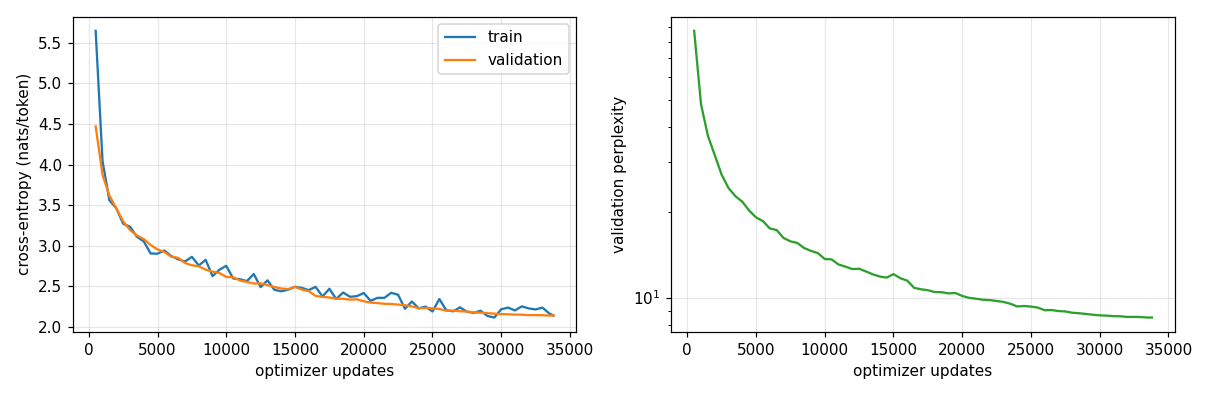

In [16]:
# CELL 15 — Training / validation curves (from the checkpoint history)
import matplotlib; matplotlib.use("Agg")
import matplotlib.pyplot as plt
hist = json.load(open(os.path.join(CKPT_DIR, "history.json")))
print(f"{'update':>7} {'tokens(M)':>10} {'train loss':>11} {'val loss':>9} {'val ppl':>9} {'lr':>9} {'min':>7}")
for h in hist[-12:]:
    print(f"{h['update']:>7} {h['tokens']/1e6:>10.1f} {h['train_loss']:>11.4f} {h['val_loss']:>9.4f} {h['val_ppl']:>9.2f} {h['lr']:>9.2e} {h['minutes']:>7.1f}")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot([h["update"] for h in hist], [h["train_loss"] for h in hist], label="train"); ax[0].plot([h["update"] for h in hist], [h["val_loss"] for h in hist], label="validation")
ax[0].set_xlabel("optimizer updates"); ax[0].set_ylabel("cross-entropy (nats/token)"); ax[0].legend(); ax[0].grid(alpha=.3)
ax[1].plot([h["update"] for h in hist], [h["val_ppl"] for h in hist], color="C2"); ax[1].set_xlabel("optimizer updates"); ax[1].set_ylabel("validation perplexity"); ax[1].set_yscale("log"); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.savefig(os.path.join(WORK, "curves.png"), dpi=110)
try:
    from IPython.display import Image, display; display(Image(os.path.join(WORK, "curves.png")))
except Exception: pass


## CELL 16 — Best-model loading + held-out decoding evaluation (ROUGE-L, BLEU-4, optional BERTScore)

In [17]:
# CELL 16 — Load the BEST checkpoint + held-out evaluation of decoding settings (ROUGE-L, BLEU-4, optional BERTScore)
from ret_gen import load_model_from_ckpt, generate_batch, to_exact_words, rouge_l_f1, bleu4
BEST = _newest(_find(lambda f, d: f == "best.pt", [CKPT_DIR, INPUT_ROOT])) or os.path.join(CKPT_DIR, "last.pt")
dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model, ck = load_model_from_ckpt(BEST, dev)
print(f"loaded {BEST} | update {ck['global_step']} | best val loss {ck['best_val']:.4f} (ppl {math.exp(ck['best_val']):.2f})")

def heldout_examples(n, seed=0):
    """512-word prompt + the true next 128 words from VALIDATION documents (never trained on)."""
    rng, out = random.Random(seed), []
    idx = list(range(val_c.n_docs)); rng.shuffle(idx)
    for i in idx:
        w = tok.decode(np.asarray(val_c.doc(i))[1:-1].tolist()).split()
        if len(w) >= 640:
            s = rng.randint(0, len(w) - 640); out.append((" ".join(w[s:s + 512]), " ".join(w[s + 512:s + 640])))
        if len(out) == n: break
    for s in range(n - len(out)):
        w = long_text(val_c, s * 3, 640).split(); out.append((" ".join(w[:512]), " ".join(w[512:640])))
    return out
EX = heldout_examples(96 if not DEBUG_TINY else 6)

# optional: BERTScore on held-out data.  A pretrained scorer is used ONLY to MEASURE (never in training or generation).
# Needs `pip install bert-score` and roberta-large (internet, or attach it as a Kaggle dataset and put the folder path in BERTSCORE_MODEL).
RUN_BERTSCORE, BERTSCORE_MODEL, BERTSCORE_LAYERS = False, "roberta-large", 17
def bertscore_f1(refs, hyps):
    from bert_score import score
    return float(score(hyps, refs, model_type=BERTSCORE_MODEL, num_layers=BERTSCORE_LAYERS, lang="en", batch_size=32, verbose=False)[2].mean())

GEN_VARIANTS = {"greedy+rep1.1+ngram4": dict(GEN),
                "greedy+rep1.05+ngram4": dict(GEN, rep_penalty=1.05),
                "greedy+rep1.2+ngram3": dict(GEN, rep_penalty=1.2, no_repeat_ngram=3),
                "greedy (no penalties)": dict(GEN, rep_penalty=1.0, no_repeat_ngram=0),
                "sample T=0.7 top-p 0.9": dict(GEN, do_sample=True, temperature=0.7, top_p=0.9, top_k=40)}
BS_EVAL = 32 if dev.type == "cuda" else 4
results = {}
for name, g in GEN_VARIANTS.items():
    hyps = []
    for i in range(0, len(EX), BS_EVAL):
        outs = generate_batch(model, tok, [p for p, _ in EX[i:i + BS_EVAL]], g, device=dev.type)
        hyps += [to_exact_words(o, g["n_words"]) for o in outs]
    refs = [r for _, r in EX]
    r_l, b4 = np.mean([rouge_l_f1(r, h) for r, h in zip(refs, hyps)]), bleu4(refs, hyps)
    line = f"{name:26s} ROUGE-L F1 = {r_l:.4f} | BLEU-4 = {b4:.4f} | distinct-1 = {np.mean([len(set(h.split()))/128 for h in hyps]):.2f}"
    if RUN_BERTSCORE:
        try: bs = bertscore_f1(refs, hyps); line += f" | BERTScore F1 = {bs:.4f}"; results[name] = (bs, g)
        except Exception as e: line += f" | BERTScore unavailable ({type(e).__name__}: {str(e)[:60]})"
    results.setdefault(name, (r_l, g)); print(line)
print("\nPROMPT (tail):", EX[0][0][-300:].replace("\n", " "), "\nTRUE   :", EX[0][1][:300].replace("\n", " "), "\nMODEL  :", hyps[0][:300].replace("\n", " "))
best_name = max(results, key=lambda k: results[k][0])
print(f"\nbest decoding setting by the chosen metric: {best_name}  -> to use it for the official run:  GEN = GEN_VARIANTS['{best_name}']")


loaded /kaggle/working/retnet/ckpt/best.pt | update 33500 | best val loss 2.1405 (ppl 8.50)
greedy+rep1.1+ngram4       ROUGE-L F1 = 0.2045 | BLEU-4 = 0.0763 | distinct-1 = 0.59
greedy+rep1.05+ngram4      ROUGE-L F1 = 0.2048 | BLEU-4 = 0.0785 | distinct-1 = 0.55
greedy+rep1.2+ngram3       ROUGE-L F1 = 0.1966 | BLEU-4 = 0.0744 | distinct-1 = 0.70
greedy (no penalties)      ROUGE-L F1 = 0.1980 | BLEU-4 = 0.0643 | distinct-1 = 0.27
sample T=0.7 top-p 0.9     ROUGE-L F1 = 0.1995 | BLEU-4 = 0.0746 | distinct-1 = 0.65

PROMPT (tail): A by virtue of the Legal Metrology Act, the definition of sale under the Legal Metrology Act has to be adopted and not the definition of sale under the Central Sales Tax (CST) Act as proposed by the Ld. A.R. appearing on behalf of the Revenue. There is no sale involved as the STBs are being supplied 
TRUE   : free, unlike during the period prior to 1/4/2012 when the appellant were giving CPE including STB on rental basis which attracted deemed sale liability unde

## CELL 17 — Official test inference

In [18]:
# CELL 17 — Official Phase-1 test inference (resumable: partial results are saved every few batches)
assert TEST_JSON and os.path.exists(TEST_JSON), "Set TEST_JSON in CELL 2 to the official test file"
test = json.load(open(TEST_JSON))
def _prompt(v): return v["text"] if isinstance(v, dict) else v
TEST_IDS = list(test.keys()); PROMPTS = {k: _prompt(test[k]) for k in TEST_IDS}
print(f"{len(TEST_IDS)} test prompts | words in first prompt: {len(PROMPTS[TEST_IDS[0]].split())}")
INF_BS = 64 if dev.type == "cuda" else 4
PART = os.path.join(WORK, "preds_partial.json")
preds = json.load(open(PART)) if os.path.exists(PART) else {}
todo = sorted([k for k in TEST_IDS if k not in preds], key=lambda k: len(PROMPTS[k]))     # similar lengths -> little padding
print(f"already done: {len(preds)} | to do: {len(todo)} | batch size {INF_BS} | GEN = {GEN}")
t0, padded = time.time(), 0
for bi in range(0, len(todo), INF_BS):
    ids = todo[bi:bi + INF_BS]
    outs = generate_batch(model, tok, [PROMPTS[k] for k in ids], GEN, device=dev.type)
    for k, o in zip(ids, outs):
        padded += len(o.split()) < GEN["n_words"]
        preds[k] = to_exact_words(o, GEN["n_words"])
    if (bi // INF_BS) % 5 == 4 or bi + INF_BS >= len(todo):
        json.dump(preds, open(PART, "w"))
        el = time.time() - t0; done_n = min(bi + INF_BS, len(todo))
        print(f"  {done_n}/{len(todo)} prompts | {el/60:.1f} min | ETA {(el/done_n*(len(todo)-done_n))/60:.1f} min")
print(f"generation finished: {len(preds)} predictions; {padded} needed word padding (generation ended with < 128 words)")


1000 test prompts | words in first prompt: 512
already done: 0 | to do: 1000 | batch size 64 | GEN = {'n_words': 128, 'do_sample': False, 'temperature': 0.8, 'top_k': 50, 'top_p': 0.92, 'rep_penalty': 1.1, 'rep_window': 128, 'no_repeat_ngram': 4, 'max_new_tokens': 450}
  320/1000 prompts | 1.3 min | ETA 2.8 min
  640/1000 prompts | 2.5 min | ETA 1.4 min
  960/1000 prompts | 3.5 min | ETA 0.1 min
  1000/1000 prompts | 3.8 min | ETA 0.0 min
generation finished: 1000 predictions; 3 needed word padding (generation ended with < 128 words)


## CELL 18 — prediction.json, verification, submission.zip

In [19]:
# CELL 18 — prediction.json + verification + submission.zip  (continuation ONLY, exactly 128 words, ID-keyed)
def verify_predictions(pred, test_dict, n_words=128):
    problems = []
    if set(pred.keys()) != set(test_dict.keys()):
        problems.append(f"ID mismatch: missing={len(set(test_dict)-set(pred))}, extra={len(set(pred)-set(test_dict))}")
    for k, v in pred.items():
        txt = v["text"] if isinstance(v, dict) else None
        if not isinstance(txt, str) or not txt.strip(): problems.append(f"{k}: empty/invalid"); continue
        if len(txt.split()) != n_words: problems.append(f"{k}: {len(txt.split())} words")
        if k in test_dict:
            pw = _prompt(test_dict[k]).split()
            if " ".join(pw[-12:]) in txt or txt.split()[:12] == pw[:12] or txt.strip() in " ".join(pw): problems.append(f"{k}: prompt text leaked into prediction")
    return problems

PRED_PATH = os.path.join(SUBMIT_DIR, "prediction.json"); ZIP_PATH = os.path.join(SUBMIT_DIR, "submission.zip")
prediction = {k: {"text": preds[k]} for k in TEST_IDS}            # same key order/type as the official test file
problems = verify_predictions(prediction, test)
print("verification problems:", problems[:10] if problems else "NONE")
assert not problems, "fix the problems above before zipping"
with open(PRED_PATH, "w", encoding="utf-8") as f: json.dump(prediction, f, ensure_ascii=False)
with zipfile.ZipFile(ZIP_PATH, "w", zipfile.ZIP_DEFLATED) as z: z.write(PRED_PATH, arcname="prediction.json")   # at the ZIP root
print(f"wrote {PRED_PATH} and {ZIP_PATH} ({os.path.getsize(ZIP_PATH)/2**20:.2f} MB)")


verification problems: NONE
wrote /kaggle/working/prediction.json and /kaggle/working/submission.zip (0.19 MB)
